# 현재 데이터로 Linux 게임 추천 실험을 할 수 있는지 확인하기

이 노트북은 추천 모델을 만들기 전에, 가진 자료만으로 실험과 평가가 가능한지 살펴본다. 추천 모델의 학습·조정·성능 비교는 하지 않는다.

**이 노트북에서 쓰는 말**
- **A·B·C**: A는 학습 자료, B는 외부 평가 자료, C는 게임 설명 보완 자료다. 자료 사이의 사용자 ID는 연결하지 않고, 게임은 Steam App ID로만 연결한다.
- **입력**: 추천을 받을 사용자의 보유 게임 목록이다.
- **정답**: 평가에서 맞혀야 하는 게임으로, B에서 긍정 평가한 공식 Linux 게임이다. B는 평가에만 쓰고 모델이나 설정값을 고르는 데 쓰지 않는다.
- **후보**: 추천 목록에 올릴 수 있는 게임이다.
- **쌍**: 사용자 한 명과 게임 한 개의 관계다.
- **공동 출현과 이웃**: 같은 사용자가 두 게임을 모두 긍정 평가하면 공동 출현이라 하고, 이렇게 이어진 다른 게임을 이웃이라 한다.
- **k-core**: 사용자별·게임별 최소 긍정 리뷰 수 기준을 반복 적용해 활동이 적은 기록을 걷어 낸 자료다.
- **TF-IDF**: 단어의 중요도를 계산해 태그와 설명을 수치로 바꾸는 방법이다.
- **신뢰구간**: 사용자를 다시 뽑아 평균 점수가 얼마나 흔들리는지 계산한 범위다(bootstrap).

**시작 전에 정한 기준** (자료를 해석하기 위한 최소 기준이며, 모델의 정확도를 보장하지 않는다 *(추정)*)
- 긍정 사용자를 5명 이상 공유하는 이웃이 20개 이상이면 이웃이 충분하다고 본다.
- 게임별 지표는 정답이 5쌍 이상인 게임에서만 해석한다.
- 보유 게임의 50% 이상이 A에 없으면 입력 손실이 크다고 본다.
- 신뢰구간은 사용자 단위로 1,000회 다시 뽑아(seed 42) 95% 범위로 계산한다.

**다시 실행하는 순서** (`EDA` 폴더 기준): 원본 내려받기 → `scripts/preprocess.py` → `python scripts/build_notebook.py 02_eda_data_sufficiency`

In [1]:
import ast
import gc
import hashlib
import json
import re
import sys
import subprocess
import time
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse, stats

EDA = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(EDA/'scripts'))
from readable_labels import column_label, display_readable as display, display_value, setup_korean_font, write_table_guide

# 계산 결과 사전이 영문 키 그대로 출력되지 않게 한다. 보여 줄 표는 display()로 출력한다.
get_ipython().ast_node_interactivity='none'
P, FIG, REP = EDA/'data'/'processed', EDA/'figures', EDA/'reports'
TAB = REP/'tables'
for d in (FIG,TAB): d.mkdir(parents=True,exist_ok=True)
RESULTS = {'tables': {}}
START = time.monotonic()

def _py(v):
    if isinstance(v, dict): return {str(k):_py(x) for k,x in v.items()}
    if isinstance(v, (list,tuple,set,np.ndarray)): return [_py(x) for x in v]
    if isinstance(v, (pd.Timestamp,)): return v.isoformat()
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.bool_,)): return bool(v)
    if isinstance(v, (np.floating,float)):
        return float(v) if np.isfinite(v) else None
    if v is pd.NA or v is pd.NaT: return None
    return v

def rec(key,value):
    RESULTS[key] = _py(value)
    return value

def save_table(df,name,index=False):
    assert int(name.split('_')[0]) >= 7, name
    df.to_csv(TAB/f'{name}.csv',index=index,encoding='utf-8-sig')
    RESULTS['tables'][name] = _py(df.reset_index().to_dict('records') if index else df.to_dict('records'))
    return df

def qtable(s,qs=(.25,.5,.75,.9,.99)):
    s=pd.Series(s,dtype='float64').dropna()
    return {'n':len(s),'min':float(s.min()) if len(s) else None,
            **{f'p{int(q*100)}':float(s.quantile(q)) if len(s) else None for q in qs},
            'mean':float(s.mean()) if len(s) else None,'max':float(s.max()) if len(s) else None}

BLUE,ORANGE,AQUA,YELLOW='#2a78d6','#eb6834','#1baf7a','#eda100'
INK,INK2,GRID='#0b0b0b','#52514e','#e6e5e0'
plt.rcParams.update({'figure.facecolor':'#fcfcfb','axes.facecolor':'#fcfcfb','savefig.facecolor':'#fcfcfb',
    'axes.edgecolor':INK2,'axes.labelcolor':INK,'xtick.color':INK2,'ytick.color':INK2,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'axes.axisbelow':True,
    'grid.color':GRID,'grid.linewidth':.8,'axes.prop_cycle':plt.cycler(color=[BLUE,ORANGE,AQUA,YELLOW]),
    'lines.linewidth':2,'font.size':10,'axes.titlesize':11,'axes.titleweight':'bold','legend.frameon':False})
pd.set_option('display.max_columns',30)
assert setup_korean_font(),'그래프에 쓸 한글 글꼴을 찾지 못했다.'
def save_fig(fig,name):
    assert int(name[3:5])>=7
    fig.savefig(FIG/f'{name}.png',dpi=150,bbox_inches='tight')

rec('criteria',{'cooccurrence_users':5,'minimum_neighbors':20,'minimum_game_target_pairs':5,
    'large_input_loss_fraction':.5,'bootstrap_iterations':1000,'bootstrap_seed':42,'confidence_level':.95});

## 준비 1. 내려받은 파일이 기록과 같은지 확인
B의 파일 하나는 Kaggle 명령줄 도구로 바로 받으면 오류가 난다. 내용이 JSON이 아니라 Python 형식으로 적혀 있는데 도구가 JSON으로 읽으려 하기 때문이다.
그래서 자료 전체 ZIP을 받은 뒤 `bundle_data.json`만 꺼내 썼다.
같은 ZIP에 든 `steam_new.json`은 꺼내거나 분석하지 않으며, 파일 지문(SHA-256) 확인 대상에서도 뺀다.

In [2]:
manifest=json.loads((EDA/'data/raw/manifest.json').read_text('utf-8'))
verification=[]
for key in ['A','B','C']:
    for f in manifest[key]['files']:
        if f['partial_head_bytes']: continue
        p=EDA/f['local_path']; h=hashlib.sha256()
        with p.open('rb') as fh:
            for block in iter(lambda:fh.read(8*1024*1024),b''): h.update(block)
        row={'dataset':key,'file':f['kaggle_file'],'local_path':f['local_path'],
             'expected_bytes':f['local_bytes'],'actual_bytes':p.stat().st_size,
             'expected_sha256':f['sha256'],'actual_sha256':h.hexdigest()}
        row.update(size_match=row['actual_bytes']==row['expected_bytes'],sha256_match=row['actual_sha256']==row['expected_sha256'])
        row['status']='match' if row['size_match'] and row['sha256_match'] else 'mismatch'
        verification.append(row)
assert len(verification)==9 and all(r['status']=='match' for r in verification), verification
pd.DataFrame(verification).to_csv(TAB/'06_cli_file_verification.csv',index=False,encoding='utf-8-sig')
assert not (EDA/'data/raw/_kaggle_tmp').exists()
manifest_diff=subprocess.check_output(['git','diff','--','EDA/data/raw/manifest.json'],cwd=EDA.parent,text=True)
assert not manifest_diff
rec('preparation',{'file_verification':verification,'verified_files':len(verification),
    'kaggle_cli_version':'2.2.5','six_version':'1.17.0','manifest_changed':False,
    'temporary_folder_removed':True,'steam_new_head_excluded':True,
    'steam_new_in_archive_not_extracted':True,'download_method':'official Kaggle CLI',
    'preprocess':'scripts/preprocess.py completed',
    'recovery':[{'problem':'처음 쓴 다운로드 스크립트가 Kaggle 자료 정보를 받지 못함(HTTP 404)',
                 'resolution':'별도 환경에 설치한 공식 Kaggle 명령줄 도구를 사용함','result':'파일 9개 확인'},
                {'problem':'`bundle_data.json`을 명령줄 도구로 받을 때 JSON 해석 오류',
                 'cause':'Python literal payload passed to the CLI JSON response parser (user-provided diagnosis)',
                 'resolution':'자료 전체 ZIP을 받아 이 파일만 꺼냄','result':'파일 크기와 내용 식별값(SHA256) 일치'}]})
print('원본 파일 확인 통과:',len(verification),'개',flush=True)

원본 파일 확인 통과: 9 개


## 준비 2. 기본 분석의 수치가 그대로 나오는지 확인
A의 중복 행은 기본 분석과 똑같이 남긴다. k-core도 기본 분석과 같이 행 수를 세어 반복 적용한다.
뒤에 나오는 공동 출현은 같은 사용자-게임 조합을 한 번만 세어 실제 사용자 수로 계산한다.
B는 사용자의 첫 프로필만 쓰고, 중복 리뷰를 없앤 뒤, 긍정과 부정이 엇갈린 기록을 제외하며, 리뷰한 게임은 모두 입력에서 뺀다.

In [3]:
A_rec=pd.read_parquet(P/'A_recommendations.parquet',columns=['user_id','app_id','is_recommended','date','helpful','funny'])
A_games=pd.read_parquet(P/'A_games.parquet')
A_meta=pd.read_parquet(P/'A_games_metadata.parquet')
B_prof=pd.read_parquet(P/'B_users_items_profiles.parquet',columns=['user_id','line_no'])
B_items=pd.read_parquet(P/'B_users_items.parquet',columns=['line_no','user_id','item_id','item_name','playtime_forever'])
B_rev=pd.read_parquet(P/'B_reviews.parquet',columns=['user_id','item_id','recommend','posted_date'])
B_sg=pd.read_parquet(P/'B_steam_games.parquet',columns=['id','app_name','title','genres','tags','specs','release_date'])
B_bun=pd.read_parquet(P/'B_bundle_items.parquet',columns=['bundle_id','item_id'])
C=pd.read_parquet(P/'C_games_2025.parquet',columns=['appid','name','linux','tags','genres','categories','short_description','about_the_game','release_date'])
assert (len(A_rec),A_rec.user_id.nunique(),A_rec.app_id.nunique())==(41154794,13781059,37610)
lin_ids=set(A_games.app_id[A_games.linux])
A_items=set(A_rec.app_id.unique())
L_all=lin_ids&A_items
assert (len(lin_ids),len(L_all))==(9041,6630)
pos_dates=A_rec.loc[A_rec.is_recommended,['user_id','app_id','date']]
pos_pairs=pos_dates[['user_id','app_id']]
i_pos=pos_pairs.groupby('app_id').size()
i_cnt=A_rec.groupby('app_id').size()
pop_A=i_pos[i_pos.index.isin(lin_ids)].sort_values(ascending=False)

def kcore(df,ku,ki,max_iter=30):
    for _ in range(max_iter):
        before=len(df)
        df=df[df.groupby('app_id').user_id.transform('size')>=ki]
        df=df[df.groupby('user_id').app_id.transform('size')>=ku]
        if len(df)==before: break
    return df

k=kcore(pos_pairs,5,10)
assert (k.user_id.nunique(),k.app_id.nunique(),len(k),len(set(k.app_id)&lin_ids))==(1621480,26064,17986052,5195)
print('A 자료와 k-core 수치가 기본 분석과 같음을 확인했다.',flush=True)

A 자료와 k-core 수치가 기본 분석과 같음을 확인했다.


In [4]:
conflict=B_rev.dropna(subset=['item_id']).groupby(['user_id','item_id']).recommend.nunique().gt(1)
first_line=B_prof.groupby('user_id').line_no.min()
Bi=(B_items[B_items.line_no.isin(first_line.values)].drop_duplicates(['user_id','item_id'])[['user_id','item_id','playtime_forever']])
conf_pairs=conflict[conflict].reset_index()[['user_id','item_id']]
Br=(B_rev.dropna(subset=['item_id']).drop_duplicates(['user_id','item_id','recommend'])
    .merge(conf_pairs.assign(_c=1),on=['user_id','item_id'],how='left'))
Br=Br[Br._c.isna()].drop(columns='_c')
cf_items=set(i_pos.index[i_pos>=10])
L_cf=lin_ids&cf_items
reviewed=Br.groupby('user_id').item_id.agg(set)
targets_all=Br[Br.recommend&Br.item_id.isin(L_all)].groupby('user_id').item_id.agg(set)
Bi_A=Bi[Bi.item_id.isin(A_items)]
inp_owned=Bi_A.groupby('user_id').item_id.agg(set)
inp_played=Bi_A[Bi_A.playtime_forever>0].groupby('user_id').item_id.agg(set)
users=targets_all.index
ev=pd.DataFrame(index=users)
ev['targets']=targets_all
ev['targets_cf']=ev.targets.map(lambda t:t&L_cf)
rv=reviewed.reindex(users)
ev['input_owned']=[inp_owned.get(u,set())-rv[u] for u in users]
ev['input_played']=[inp_played.get(u,set())-rv[u] for u in users]
ev['input_owned_cf']=ev.input_owned.map(lambda s:s&cf_items)
for c in ['targets','targets_cf','input_owned','input_played','input_owned_cf']: ev['n_'+c]=ev[c].map(len)
assert all(not(t&i) for t,i in zip(ev.targets,ev.input_owned))
sub=ev[(ev.n_targets>=1)&(ev.n_input_owned>=5)]
assert (len(sub),sub.n_targets.sum(),len(set().union(*sub.targets)))==(15294,24704,829)

# Unknown review years remain unknown; a training cutoff alone is not a
# chronological split because known B targets can predate the cutoff too.
b_target_pairs = sub.targets.explode().rename('item_id').reset_index()
b_pair_dates = B_rev.groupby(['user_id','item_id']).posted_date.max()
b_target_dates = b_pair_dates.reindex(pd.MultiIndex.from_frame(b_target_pairs[['user_id','item_id']]))
rec('A_external_target_dates',{
    'target_pairs':len(b_target_dates),'unknown_date_target_pairs':int(b_target_dates.isna().sum()),
    'unknown_date_target_pairs_pct':float(b_target_dates.isna().mean()*100),
    'known_target_pairs_on_or_before_2015_12_31':int(b_target_dates.le('2015-12-31').sum()),
    'known_target_date_min':b_target_dates.min(),'known_target_date_max':b_target_dates.max(),
    'chronological_test':False,
    'note':'B ownership has no acquisition timestamps; A training-period restriction alone cannot establish historical input availability.',
})

def per_user_topk(ev_df,scores,k_top=10):
    order=scores.sort_values(ascending=False).index.to_numpy()
    disc=1/np.log2(np.arange(2,k_top+2))
    rows=[]
    for uid,inp,tgt in zip(ev_df.index,ev_df.input_owned,ev_df.targets):
        top=[i for i in order[:k_top+len(inp)] if i not in inp][:k_top]
        hits=np.array([i in tgt for i in top],dtype=float)
        rows.append((uid,hits.sum()/len(tgt),(hits*disc[:len(hits)]).sum()/disc[:min(len(tgt),k_top)].sum()))
    return pd.DataFrame(rows,columns=['user_id','recall','ndcg'])

base_users=per_user_topk(sub,pop_A)
baseline=base_users[['recall','ndcg']].mean()
assert round(baseline.recall,4)==.5386 and round(baseline.ndcg,4)==.3731,baseline
reproduction={'A_reviews':len(A_rec),'A_users':A_rec.user_id.nunique(),'A_reviewed_games':len(A_items),
    'linux_games':len(lin_ids),'linux_reviewed_games':len(L_all),'kcore_users':k.user_id.nunique(),
    'kcore_games':k.app_id.nunique(),'kcore_interactions':len(k),'kcore_linux_games':len(set(k.app_id)&lin_ids),
    'evaluation_users':len(sub),'target_pairs':int(sub.n_targets.sum()),'target_games':len(set().union(*sub.targets)),
    'pop_recall10':float(baseline.recall),'pop_ndcg10':float(baseline.ndcg),'asserts_passed':True}
rec('reproduction',reproduction)
save_table(pd.DataFrame([reproduction]),'07_reproduction')
print('기본 분석의 주요 수치가 모두 그대로 재현됐다.',flush=True)
display(reproduction)

기본 분석의 주요 수치가 모두 그대로 재현됐다.


,항목,값
0,A 리뷰 수,"41,154,794"
1,A 리뷰 작성 사용자 수,"13,781,059"
2,A 리뷰가 있는 게임 수,"37,610"
3,Linux 게임 수,"9,041"
4,리뷰가 있는 Linux 게임 수,"6,630"
5,k-core에 남은 사용자 수,"1,621,480"
6,k-core에 남은 게임 수,"26,064"
7,k-core에 남은 사용자-게임 상호작용 수,"17,986,052"
8,k-core에 남은 Linux 게임 수,"5,195"
9,평가 사용자 수,"15,294"


## 1. 추천 결과를 확인할 긍정 리뷰가 충분한가?
정답 기록이 없는 후보를 "좋아하지 않는 게임"으로 보면 안 된다. 평가 자료에서 확인할 수 없는 게임일 뿐이다.
인기 구간은 A 긍정 리뷰 수 기준 0 / 1–9 / 10–49 / 50–199 / 200–999 / 1,000건 이상으로 미리 고정했다.
장르는 C를 먼저 쓰고 없으면 B에서 가져오며, 게임은 App ID로만 연결한다. 장르가 여러 개인 게임은 장르마다 한 번씩 센다.

In [5]:
def parse_labels(value):
    if value is None: return []
    if isinstance(value,str):
        if value.strip() in ('','{}','[]'): return []
        try: value=ast.literal_eval(value)
        except (ValueError,SyntaxError): return []
    if isinstance(value,dict): value=list(value)
    if isinstance(value,(list,tuple,set,np.ndarray)): return [str(x).strip().casefold() for x in value if str(x).strip()]
    return []

def popularity_band(s):
    return pd.cut(s,[-1,0,9,49,199,999,np.inf],labels=['0','1-9','10-49','50-199','200-999','1000+']).astype(str)

tgt_cnt=pd.Series([int(i) for t in sub.targets for i in t],dtype='int64').value_counts()
a_items=A_games[A_games.app_id.isin(L_all)][['app_id','title','date_release']].copy()
a_items['positive_reviews']=a_items.app_id.map(i_pos).fillna(0).astype(int)
a_items['target_pairs']=a_items.app_id.map(tgt_cnt).fillna(0).astype(int)
a_items['evaluated']=a_items.target_pairs.gt(0)
a_items['year']=a_items.date_release.dt.year
a_items['popularity_band']=popularity_band(a_items.positive_reviews)
c_genres=C.set_index('appid').genres.map(parse_labels).to_dict()
b_genres=B_sg.dropna(subset=['id']).drop_duplicates('id').set_index('id').genres.map(parse_labels).to_dict()
a_items['genres']=a_items.app_id.map(lambda i:c_genres.get(i,[]) or b_genres.get(i,[]) or ['unknown'])
save_table(a_items,'07_candidate_labels')
a_comparisons=[]
for field in ['year','popularity_band','genres']:
    d=a_items.explode('genres') if field=='genres' else a_items
    if field=='genres':
        major=d[field].value_counts().head(15).index
        d=d[d[field].isin(major)]
    for category,g in d.groupby(field,dropna=False,observed=True):
        a_comparisons.append({'dimension':field,'category':str(category),'candidates':len(g),
            'target_games':int(g.evaluated.sum()),'unlabeled_games':int((~g.evaluated).sum()),
            'unlabeled_pct':float((~g.evaluated).mean()*100),'target_pairs':int(g.target_pairs.sum()),
            'share_of_all_candidates_pct':len(g)/len(a_items)*100,
            'share_of_target_games_pct':g.evaluated.sum()/len(tgt_cnt)*100})
save_table(pd.DataFrame(a_comparisons),'07_candidate_target_comparison')
rec('A_label_coverage',{'candidates':len(a_items),'target_games':len(tgt_cnt),
    'unlabeled_games':int((~a_items.evaluated).sum()),'unlabeled_pct':float((~a_items.evaluated).mean()*100),
    'target_pair_distribution':qtable(tgt_cnt),'games_with_exactly_1_target':int(tgt_cnt.eq(1).sum()),
    'games_with_ge5_targets':int(tgt_cnt.ge(5).sum()),'games_with_ge10_targets':int(tgt_cnt.ge(10).sum()),
    'ge5_games_share_candidates_pct':float(tgt_cnt.ge(5).sum()/len(a_items)*100)})

In [6]:
tail_rows=[]
for nhead in [10,50,100,200]:
    head=set(pop_A.index[:nhead])
    tails=sub.targets.map(lambda s:s-head)
    keep=tails.map(bool)
    tail_rows.append({'excluded_head_games':nhead,'users':int(keep.sum()),
        'target_pairs':int(tails.map(len).sum()),'target_games':len(set().union(*tails[keep]))})
save_table(pd.DataFrame(tail_rows),'07_longtail_sensitivity')
rec('A_longtail_sensitivity',tail_rows)
head50=set(pop_A.index[:50])
sub_lt=sub.assign(targets=sub.targets.map(lambda s:s-head50))
sub_lt=sub_lt[sub_lt.targets.map(len)>0]

def bootstrap_baseline(label,frame,scores):
    values=per_user_topk(frame,scores)[['recall','ndcg']].to_numpy()
    rng=np.random.default_rng(42)
    bootstrap=np.empty((1000,2))
    for start in range(0,1000,50):
        idx=rng.integers(0,len(values),size=(min(50,1000-start),len(values)))
        bootstrap[start:start+len(idx)]=values[idx].mean(axis=1)
    rows=[]
    for j,name in enumerate(['Recall@10','NDCG@10']):
        lo,hi=np.quantile(bootstrap[:,j],[.025,.975])
        rows.append({'population':label,'users':len(frame),'metric':name,'estimate':values[:,j].mean(),
            'ci_low':lo,'ci_high':hi,'ci_width':hi-lo,'iterations':1000,'seed':42})
    return rows

a_ci=[]
for label,frame,scores in [('all',sub,pop_A),('longtail_full_candidates',sub_lt,pop_A),
    ('longtail_head50_excluded_candidates',sub_lt,pop_A[~pop_A.index.isin(head50)])]:
    a_ci.extend(bootstrap_baseline(label,frame,scores))
save_table(pd.DataFrame(a_ci),'07_popularity_bootstrap_ci')
rec('A_baseline_bootstrap',a_ci)

신뢰구간은 인기순 추천의 평균 점수가 표본에 따라 얼마나 흔들리는지 보여 준다. 두 모델의 차이를 어디까지 구분할 수 있는지는 사용자별 점수 차이, 두 모델 점수의 상관, 목표 검정력(실제 차이를 찾아낼 확률)에 달려 있어 여기서 정할 수 없다.
인기 상위 게임을 정답에서 뺀 평가에서 후보를 전체로 두면 인기순 추천의 점수는 0이 된다. 이때 신뢰구간도 0이지만, 판단력이 높다는 뜻은 아니다.
실제 모델을 비교할 때는 A 안에서만 조정한 모델을 고정하고, 같은 사용자의 점수 차이를 다시 뽑아 보는 방식(paired bootstrap)으로 평가해야 한다 *(추정)*.

In [7]:
temporal=[]
for cut in ['2021-01-01','2022-01-01']:
    before=pos_dates.date<pd.Timestamp(cut)
    prior=pos_dates.loc[before].groupby('user_id').size()
    eligible=prior.index[prior>=5]
    future=pos_dates.loc[~before & pos_dates.app_id.isin(lin_ids) & pos_dates.user_id.isin(eligible),['user_id','app_id']].drop_duplicates()
    all_prior_items=set(A_rec.app_id[A_rec.date<pd.Timestamp(cut)])
    new=~future.app_id.isin(all_prior_items)
    target_ids=set(future.app_id)
    temporal.append({'cutoff':cut,'users':future.user_id.nunique(),'target_pairs':len(future),
        'target_games':len(target_ids),'new_target_games':len(target_ids-all_prior_items),
        'new_target_game_pct':len(target_ids-all_prior_items)/len(target_ids)*100,
        'new_target_pairs':int(new.sum()),'new_target_pair_pct':float(new.mean()*100),
        'prior_positive_requirement':5})
save_table(pd.DataFrame(temporal),'07_A_internal_time_split')
rec('A_internal_time_split',temporal)
k_linux=k[k.app_id.isin(lin_ids)]
user_linux=k_linux.groupby('user_id').app_id.nunique()
eligible=user_linux.index[user_linux>=2]
rec('A_internal_holdout',{'eligible_kcore_users':len(eligible),
    'possible_target_games':k_linux.app_id[k_linux.user_id.isin(eligible)].nunique(),
    'definition':'At least two distinct Linux positive games per k-core user; counts possible targets, no split or model was fitted.'})
del k_linux
pre_pairs=pos_dates.loc[pos_dates.date<='2015-12-31',['user_id','app_id']]
pre_rows=[]
for ku,ki in [(1,1),(2,5),(3,10),(5,10),(5,20),(10,20)]:
    core_pre=kcore(pre_pairs,ku,ki)
    pre_rows.append({'min_user_pos':ku,'min_item_pos':ki,'users':core_pre.user_id.nunique(),
        'games':core_pre.app_id.nunique(),'interactions':len(core_pre),
        'linux_games':len(set(core_pre.app_id)&lin_ids),'linux_interactions':int(core_pre.app_id.isin(lin_ids).sum())})
save_table(pd.DataFrame(pre_rows),'07_pre2016_kcore')
rec('A_pre2016_kcore',pre_rows)
del core_pre,pre_pairs
gc.collect()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(tgt_cnt,bins=np.geomspace(1,int(tgt_cnt.max())+1,30),color=BLUE)
axes[0].set(xscale='log',yscale='log',xlabel='게임별 정답 쌍 수',ylabel='게임 수',title='B 자료: 게임별 정답 수 분포')
tail_df=pd.DataFrame(tail_rows)
axes[1].plot(tail_df.excluded_head_games,tail_df.target_pairs,marker='o',color=ORANGE)
axes[1].set(xlabel='제외한 인기 Linux 게임 수',ylabel='남은 정답 쌍 수',title='인기 게임을 뺄수록 줄어드는 정답 수')
fig.tight_layout();save_fig(fig,'fig07_label_sufficiency');plt.close(fig)
print('1절 계산 완료: 정답 규모와 A 내부 평가 가능 범위',flush=True)

1절 계산 완료: 정답 규모와 A 내부 평가 가능 범위


## 2. 같은 사용자가 좋아한 게임끼리 연결할 수 있는가?
Item-KNN은 함께 긍정 평가된 게임을 서로 가까운 이웃으로 보는 추천 방식이다. 여기서는 모델을 만들기 전에 이 연결이 충분한지만 센다.
사용자-게임은 긍정 여부만 보고, 자기 자신은 이웃에서 뺀다.
Linux 게임을 128개씩 나눠 계산하며, Linux 미지원 게임도 입력 쪽 이웃으로 인정한다.
후보 6,630개는 고정하고, k-core에서 빠진 게임도 이웃 0개로 계산에 넣는다.
이 값은 연결 구조를 본 것이며 추천 정확도나 유사도 순위가 아니다.

In [8]:
b_candidates=np.array(sorted(L_all),dtype=np.int64)
b_targets=np.array(sorted(tgt_cnt.index),dtype=np.int64)
b_target_index={int(i):j for j,i in enumerate(b_targets)}
b_neighbor_rows=[]
b_reach_rows=[]
b_summary=[]
for source,pairs in [('all_positive',pos_pairs),('kcore_5_10',k)]:
    item_ids=np.sort(pairs.app_id.unique())
    item_lookup={int(i):j for j,i in enumerate(item_ids)}
    cols=pd.Index(item_ids).get_indexer(pairs.app_id)
    rows=pairs.user_id.to_numpy(dtype=np.int32)
    x=sparse.csr_matrix((np.ones(len(pairs),dtype=np.int32),(rows,cols)),shape=(int(rows.max())+1,len(item_ids)))
    x.sum_duplicates();x.data[:]=1
    binary_nnz=int(x.nnz)
    xc=x.tocsc();xt=xc.T.tocsr()
    del x,cols,rows
    # This small Boolean lookup is only for the 829 observed target games, never a score matrix.
    target_adj=np.zeros((len(b_targets),len(item_ids)),dtype=bool)
    available=[int(i) for i in b_candidates if int(i) in item_lookup]
    count_map={int(i):[0,0,0,0] for i in b_candidates}
    for start in range(0,len(available),128):
        ids=available[start:start+128]
        block=(xt@xc[:,[item_lookup[i] for i in ids]]).tocsc()
        for j,item in enumerate(ids):
            lo,hi=block.indptr[j:j+2]
            neighbor=block.indices[lo:hi];counts=block.data[lo:hi]
            valid=neighbor!=item_lookup[item]
            neighbor=neighbor[valid];counts=counts[valid]
            count_map[item]=[int(np.count_nonzero(counts>=threshold)) for threshold in [1,5,10,20]]
            if item in b_target_index:
                target_adj[b_target_index[item],neighbor[counts>=5]]=True
        del block
    candidate_support=pd.Series(np.diff(xc.indptr),index=item_ids)
    for item in b_candidates:
        c=count_map[int(item)]
        b_neighbor_rows.append({'source':source,'app_id':int(item),'positive_users_in_source':int(candidate_support.get(item,0)),
            'A_positive_reviews':int(i_pos.get(item,0)),**{f'neighbors_ge{t}':n for t,n in zip([1,5,10,20],c)},
            'insufficient_ge5_neighbors':c[1]<20})
    source_df=pd.DataFrame([r for r in b_neighbor_rows if r['source']==source])
    source_df['popularity_band']=popularity_band(source_df.A_positive_reviews)
    for band,g in [('all_candidates',source_df)]+list(source_df.groupby('popularity_band',observed=True)):
        b_summary.append({'source':source,'popularity_band':band,'candidate_games':len(g),
            'insufficient_games':int(g.insufficient_ge5_neighbors.sum()),
            'insufficient_pct':float(g.insufficient_ge5_neighbors.mean()*100),
            **{f'neighbors_ge{t}_median':float(g[f'neighbors_ge{t}'].median()) for t in [1,5,10,20]},
            'neighbors_ge5_p10':float(g.neighbors_ge5.quantile(.1)),
            'neighbors_ge5_p90':float(g.neighbors_ge5.quantile(.9))})
    for population,frame in [('all',sub),('longtail_head50_excluded_targets',sub_lt)]:
        pair_n=pair_hit=user_any=user_all=0
        for inp,targets in zip(frame.input_owned,frame.targets):
            input_idx=[item_lookup[int(i)] for i in inp if int(i) in item_lookup]
            hits=[bool(target_adj[b_target_index[int(t)],input_idx].any()) if input_idx else False for t in targets]
            pair_n+=len(hits);pair_hit+=sum(hits);user_any+=any(hits);user_all+=all(hits)
        b_reach_rows.append({'source':source,'population':population,'users':len(frame),
            'target_pairs':pair_n,'reachable_target_pairs':pair_hit,'reachable_pairs_pct':pair_hit/pair_n*100,
            'users_with_any_reachable_target':user_any,'users_with_any_reachable_target_pct':user_any/len(frame)*100,
            'users_with_all_reachable_targets':user_all,'users_with_all_reachable_targets_pct':user_all/len(frame)*100,
            'minimum_cooccurrence_users':5})
    rec('B_binary_'+source,{'positive_rows':len(pairs),'distinct_positive_user_item_pairs':binary_nnz,
        'duplicate_positive_rows_collapsed':len(pairs)-binary_nnz,'items':len(item_ids),'linux_column_batch_size':128})
    print('공동 출현 계산 완료:',display_value(source,column='source'),flush=True)
    del xc,xt,target_adj
    gc.collect()
b_neighbors=pd.DataFrame(b_neighbor_rows)
b_neighbors['popularity_band']=popularity_band(b_neighbors.A_positive_reviews)
save_table(b_neighbors,'08_positive_cooccurrence_neighbors')
save_table(pd.DataFrame(b_summary),'08_positive_cooccurrence_by_popularity')
save_table(pd.DataFrame(b_reach_rows),'08_B_target_cooccurrence_reachability')
rec('B_neighbor_summary',b_summary)
rec('B_reachability',b_reach_rows)

공동 출현 계산 완료: 전체 긍정 리뷰 기준


공동 출현 계산 완료: 사용자 5건·게임 10건 이상으로 거른 기준


In [9]:
b_threshold=[]
total_inputs=int(sub.input_owned.map(len).sum())
total_targets=int(sub.targets.map(len).sum())
for threshold in [5,10,20,50]:
    allowed=set(i_pos.index[i_pos>=threshold])
    linux_allowed=L_all&allowed
    retained_input=sub.input_owned.map(lambda s:len(s&allowed))
    retained_target=sub.targets.map(lambda s:len(s&allowed))
    b_threshold.append({'positive_review_threshold':threshold,'remaining_all_items':len(allowed),
        'linux_candidates':len(linux_allowed),'linux_candidate_pct':len(linux_allowed)/len(L_all)*100,
        'B_input_pairs':int(retained_input.sum()),'B_input_pair_pct':retained_input.sum()/total_inputs*100,
        'B_target_pairs':int(retained_target.sum()),'B_target_pair_pct':retained_target.sum()/total_targets*100,
        'B_target_games':len(set(tgt_cnt.index)&allowed),'users_retaining_ge5_inputs':int(retained_input.ge(5).sum()),
        'users_retaining_any_target':int(retained_target.ge(1).sum()),
        'users_retaining_both_conditions':int((retained_input.ge(5)&retained_target.ge(1)).sum())})
save_table(pd.DataFrame(b_threshold),'09_cf_item_threshold_sensitivity')
rec('B_cf_threshold_sensitivity',b_threshold)
fig,ax=plt.subplots(figsize=(8,4.5))
for source,col in [('all_positive',BLUE),('kcore_5_10',ORANGE)]:
    values=np.sort(b_neighbors.loc[b_neighbors.source.eq(source),'neighbors_ge5'].to_numpy())
    ax.step(values,np.arange(1,len(values)+1)/len(values),where='post',label=display_value(source,column='source'),color=col)
ax.axvline(20,color=INK2,linestyle='--',linewidth=1)
ax.set(xscale='symlog',xlabel='긍정 사용자를 5명 이상 공유하는 다른 게임 수',ylabel='후보 게임의 누적 비율',title='Linux 후보 게임별 이웃 수')
ax.set_xlim(left=0)
ax.legend();fig.tight_layout();save_fig(fig,'fig08_cooccurrence_support');plt.close(fig)
print('2절 계산 완료: 유사도 순위나 상위 추천 목록은 만들지 않았다.',flush=True)

2절 계산 완료: 유사도 순위나 상위 추천 목록은 만들지 않았다.


## 3. 태그와 설명으로 게임을 비교할 수 있는가?

분석 대상은 A에서 공식 Linux 지원으로 표시된 게임 9,041개다. A 리뷰가 하나 이상 있는 Linux 게임 6,630개는 별도 행으로 함께 요약한다. 비교용 Linux 미지원 게임은 A 전체 게임에서 공식 Linux 게임을 뺀 것이다.
태그 수를 셀 때 한 게임 안의 중복 태그는 한 번으로 센다. TF-IDF 점검에는 B와 외부 평가 정답을 전혀 쓰지 않는다.

In [10]:
import ast as c_ast
from collections import Counter as c_Counter

from scipy.sparse import csr_matrix as c_csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer as c_TfidfVectorizer


def c_parse_collection(c_value):
    """Safely parse tag/genre collections; dict keys are the category labels."""
    if c_value is None:
        return [], "missing"
    if isinstance(c_value, np.ndarray):
        c_value = c_value.tolist()
    if isinstance(c_value, str):
        c_raw = c_value.strip()
        if not c_raw or c_raw.casefold() in {"{}", "[]", "()", "set()", "none", "nan"}:
            return [], "empty"
        try:
            c_value = c_ast.literal_eval(c_raw)
        except (SyntaxError, ValueError, TypeError):
            # Keep an unparseable non-empty literal as one label and count it below.
            return [c_raw.casefold()], "literal_parse_failed"
    else:
        c_missing = pd.isna(c_value)
        if isinstance(c_missing, (bool, np.bool_)) and c_missing:
            return [], "missing"

    if isinstance(c_value, dict):
        c_items = c_value.keys()
    elif isinstance(c_value, (list, tuple, set, frozenset)):
        c_items = c_value
    elif c_value is None:
        return [], "empty"
    else:
        c_items = [c_value]

    c_labels = set()
    for c_item in c_items:
        c_label = " ".join(str(c_item).strip().casefold().split())
        if c_label and c_label not in {"{}", "[]"}:
            c_labels.add(c_label)
    return sorted(c_labels), "ok" if c_labels else "empty"


def c_clean_text(c_value):
    if c_value is None:
        return ""
    c_missing = pd.isna(c_value)
    if isinstance(c_missing, (bool, np.bool_)) and c_missing:
        return ""
    return str(c_value).strip()


def c_safe_tags(c_value):
    return c_value if isinstance(c_value, list) else []


def c_safe_qtable(c_values):
    c_series = pd.Series(c_values, dtype="float64").dropna()
    return qtable(c_series) if len(c_series) else {}


def c_tag_cohort_stats(c_cohort, c_frame):
    c_docs = c_frame["A_tags"].map(c_safe_tags)
    c_tag_counts = c_Counter(c_tag for c_doc in c_docs for c_tag in sorted(set(c_doc)))
    c_doc_freq = pd.Series(c_tag_counts, dtype="int64").sort_values(ascending=False)
    c_lengths = c_docs.map(len)
    c_tag_n = len(c_doc_freq)
    c_stats = {
        "cohort": c_cohort,
        "games": int(len(c_frame)),
        "games_with_tags": int(c_lengths.gt(0).sum()),
        "tagged_games_pct": float(c_lengths.gt(0).mean() * 100) if len(c_lengths) else 0.0,
        "unique_tags": int(c_tag_n),
        "tags_per_game": c_safe_qtable(c_lengths),
        "document_frequency": c_safe_qtable(c_doc_freq.values),
        "positive_reviews_per_game": c_safe_qtable(c_frame["positive_reviews"].values),
        "tags_seen_in_fewer_than_5_games": int(c_doc_freq.lt(5).sum()),
        "tags_seen_in_fewer_than_5_games_pct": (
            float(c_doc_freq.lt(5).mean() * 100) if c_tag_n else 0.0
        ),
    }
    c_top_rows = [
        {
            "cohort": c_cohort,
            "rank": int(c_rank),
            "tag": str(c_tag),
            "document_frequency": int(c_count),
            "share_of_games_pct": float(c_count / len(c_frame) * 100) if len(c_frame) else 0.0,
        }
        for c_rank, (c_tag, c_count) in enumerate(c_doc_freq.head(20).items(), start=1)
    ]
    return c_stats, c_top_rows


def c_jaccard(c_left, c_right):
    c_union = set(c_left) | set(c_right)
    if not c_union:
        return np.nan
    return len(set(c_left) & set(c_right)) / len(c_union)


def c_description_stats(c_cohort, c_frame):
    c_desc = c_frame["A_description"].map(c_clean_text)
    c_nonempty = c_desc[c_desc.ne("")]
    c_lengths = c_nonempty.str.len()
    c_counts = c_nonempty.value_counts()
    c_repeated = c_counts[c_counts.gt(1)]
    c_ascii_ratios = []
    c_ascii_chars = 0
    c_visible_chars = 0
    for c_text in c_nonempty:
        c_chars = [c_char for c_char in c_text if not c_char.isspace()]
        c_visible_chars += len(c_chars)
        c_ascii_chars += sum(ord(c_char) < 128 for c_char in c_chars)
        c_ascii_ratios.append(
            sum(ord(c_char) < 128 for c_char in c_chars) / len(c_chars) if c_chars else np.nan
        )

    c_miss = c_desc.eq("")
    c_short = c_frame["C_short_description"].map(c_clean_text).ne("")
    c_about = c_frame["C_about_the_game"].map(c_clean_text).ne("")
    c_fill_short = c_miss & c_short
    c_fill_about = c_miss & c_about
    c_fill_either = c_miss & (c_short | c_about)
    c_has_a_or_c = ~c_miss | c_fill_either
    c_summary = {
        "cohort": c_cohort,
        "games": int(len(c_frame)),
        "A_description_missing": int(c_miss.sum()),
        "A_description_missing_pct": float(c_miss.mean() * 100) if len(c_frame) else 0.0,
        "A_description_length_chars_nonempty": c_safe_qtable(c_lengths.values),
        "exact_duplicate_description_text_groups": int(len(c_repeated)),
        "games_in_exact_duplicate_text_groups": int(c_repeated.sum()),
        "excess_games_from_exact_duplicates": int((c_repeated - 1).sum()),
        "duplicate_games_pct_of_nonempty_descriptions": (
            float(c_repeated.sum() / len(c_nonempty) * 100) if len(c_nonempty) else 0.0
        ),
        "descriptions_with_any_non_ascii_pct": (
            float((pd.Series(c_ascii_ratios).lt(1).mean()) * 100) if c_ascii_ratios else 0.0
        ),
        "description_ascii_character_share": (
            float(c_ascii_chars / c_visible_chars) if c_visible_chars else np.nan
        ),
        "per_description_ascii_character_ratio": c_safe_qtable(c_ascii_ratios),
        "C_short_description_can_fill_A_missing": int(c_fill_short.sum()),
        "C_about_the_game_can_fill_A_missing": int(c_fill_about.sum()),
        "C_both_fields_can_fill_A_missing": int((c_miss & c_short & c_about).sum()),
        "C_either_field_can_fill_A_missing": int(c_fill_either.sum()),
        "A_or_C_description_available": int(c_has_a_or_c.sum()),
        "A_or_C_description_available_pct": float(c_has_a_or_c.mean() * 100) if len(c_frame) else 0.0,
    }

    c_duplicate_rows = []
    for c_rank, (c_text, c_count) in enumerate(c_repeated.head(20).items(), start=1):
        c_duplicate_rows.append({
            "cohort": c_cohort,
            "rank": int(c_rank),
            "games": int(c_count),
            "description_length": int(len(c_text)),
            "exact_description_excerpt": c_text[:500],
        })
    return c_summary, c_duplicate_rows


def c_fit_tfidf(c_corpus, c_settings):
    c_vectorizer = c_TfidfVectorizer(
        lowercase=c_settings["lowercase"],
        strip_accents=c_settings["strip_accents"],
        ngram_range=tuple(c_settings["ngram_range"]),
        token_pattern=c_settings["token_pattern"],
        min_df=c_settings["min_df"],
        max_df=c_settings["max_df"],
        max_features=c_settings["max_features"],
        sublinear_tf=c_settings["sublinear_tf"],
        norm=c_settings["norm"],
        dtype=np.float32,
    )
    try:
        c_matrix = c_vectorizer.fit_transform(c_corpus).tocsr()
    except ValueError as c_error:
        if "empty vocabulary" not in str(c_error).casefold():
            raise
        c_vectorizer = None
        c_matrix = c_csr_matrix((len(c_corpus), 0), dtype=np.float32)
    return c_vectorizer, c_matrix


def c_nearest_similarity_stats(c_matrix, c_batch_size=256):
    """Compute row maxima and positive-neighbor counts in bounded sparse batches."""
    c_n = c_matrix.shape[0]
    c_best = np.zeros(c_n, dtype=np.float32)
    c_neighbor_counts = np.zeros(c_n, dtype=np.int32)
    for c_start in range(0, c_n, c_batch_size):
        c_stop = min(c_start + c_batch_size, c_n)
        c_sim = (c_matrix[c_start:c_stop] @ c_matrix.T).tocsr()
        # This is rectangular (batch rows × all columns), so each self-column
        # is its global row index, not the local diagonal index.
        for c_local in range(c_stop - c_start):
            c_row_start, c_row_end = c_sim.indptr[c_local], c_sim.indptr[c_local + 1]
            c_self_local = np.flatnonzero(
                c_sim.indices[c_row_start:c_row_end] == c_start + c_local
            )
            if len(c_self_local):
                c_sim.data[c_row_start + c_self_local] = 0.0
        c_sim.eliminate_zeros()
        for c_local in range(c_stop - c_start):
            c_row = c_start + c_local
            c_begin, c_end = c_sim.indptr[c_local], c_sim.indptr[c_local + 1]
            if c_end > c_begin:
                c_best[c_row] = c_sim.data[c_begin:c_end].max()
                c_neighbor_counts[c_row] = c_end - c_begin
    return c_best, c_neighbor_counts


def c_query_neighbors(c_variant, c_matrix, c_queries, c_app_ids, c_titles, c_zero_vector):
    c_rows = []
    c_id_to_title = {
        int(c_app_id): (c_title if c_title else f"App {int(c_app_id)}")
        for c_app_id, c_title in zip(c_app_ids.tolist(), c_titles.tolist())
    }
    for c_query in c_queries.itertuples(index=False):
        c_q_app_id = int(c_query.app_id)
        c_q_index = int(np.flatnonzero(c_app_ids == c_q_app_id)[0])
        c_scores = (c_matrix[c_q_index] @ c_matrix.T).toarray().ravel()
        c_scores[c_q_index] = -np.inf
        c_candidates = np.flatnonzero(np.arange(len(c_app_ids)) != c_q_index)
        c_order = c_candidates[np.lexsort((c_app_ids[c_candidates], -c_scores[c_candidates]))]
        c_positive_neighbor_count = int(np.count_nonzero(c_scores > 0))
        for c_rank, c_neighbor_index in enumerate(c_order[:5], start=1):
            c_neighbor_id = int(c_app_ids[c_neighbor_index])
            c_rows.append({
                "variant": c_variant,
                "query_stratum": c_query.popularity_stratum,
                "query_app_id": c_q_app_id,
                "query_title": c_query.title,
                "query_positive_reviews": int(c_query.positive_reviews),
                "query_zero_vector": bool(c_zero_vector[c_q_index]),
                "query_positive_similarity_neighbors": c_positive_neighbor_count,
                "rank": int(c_rank),
                "neighbor_app_id": c_neighbor_id,
                "neighbor_title": c_id_to_title.get(c_neighbor_id, f"App {c_neighbor_id}"),
                "cosine_similarity": float(c_scores[c_neighbor_index]),
                "positive_similarity": bool(c_scores[c_neighbor_index] > 0),
            })
    return c_rows


# Build an A game universe, then add Linux IDs if any are absent from the title table.
c_a_games = A_games[["app_id", "title"]].drop_duplicates("app_id").copy()
c_a_game_ids = set(c_a_games["app_id"].tolist())
c_missing_linux_ids = sorted(set(lin_ids) - c_a_game_ids)
if c_missing_linux_ids:
    c_a_games = pd.concat([
        c_a_games,
        pd.DataFrame({"app_id": c_missing_linux_ids, "title": [np.nan] * len(c_missing_linux_ids)}),
    ], ignore_index=True)
c_a_games["is_linux"] = c_a_games["app_id"].isin(lin_ids)
c_a_games["has_a_review"] = c_a_games["app_id"].isin(L_all)
c_a_games["positive_reviews"] = i_pos.reindex(c_a_games["app_id"]).fillna(0).astype("int64").to_numpy()

c_a_meta_dup_rows = int(A_meta["app_id"].duplicated().sum())
c_a_meta = A_meta[["app_id", "tags", "description"]].drop_duplicates("app_id", keep="first").copy()
c_a_meta["A_tags"] = c_a_meta["tags"].map(lambda c_value: c_parse_collection(c_value)[0])
c_a_meta["A_description"] = c_a_meta["description"].map(c_clean_text)
c_a_meta = c_a_meta[["app_id", "A_tags", "A_description"]]

c_c_dup_rows = int(C["appid"].duplicated().sum())
c_c_meta = C[["appid", "tags", "genres", "short_description", "about_the_game"]].copy()
c_c_meta["app_id"] = pd.to_numeric(c_c_meta["appid"], errors="coerce")
c_c_meta = c_c_meta.dropna(subset=["app_id"]).copy()
c_c_meta["app_id"] = c_c_meta["app_id"].astype("int64")
c_c_meta["C_tags_parsed"] = c_c_meta["tags"].map(c_parse_collection)
c_c_meta["C_genres_parsed"] = c_c_meta["genres"].map(c_parse_collection)
c_c_meta["C_tags"] = c_c_meta["C_tags_parsed"].map(lambda c_value: c_value[0])
c_c_meta["C_genres"] = c_c_meta["C_genres_parsed"].map(lambda c_value: c_value[0])
c_c_meta["C_tags_parse_status"] = c_c_meta["C_tags_parsed"].map(lambda c_value: c_value[1])
c_c_meta["C_genres_parse_status"] = c_c_meta["C_genres_parsed"].map(lambda c_value: c_value[1])
c_c_meta["C_short_description"] = c_c_meta["short_description"].map(c_clean_text)
c_c_meta["C_about_the_game"] = c_c_meta["about_the_game"].map(c_clean_text)
c_c_meta = c_c_meta.drop_duplicates("app_id", keep="first")
c_c_meta = c_c_meta[[
    "app_id", "C_tags", "C_genres", "C_tags_parse_status", "C_genres_parse_status",
    "C_short_description", "C_about_the_game",
]]

c_content = (
    c_a_games
    .merge(c_a_meta, on="app_id", how="left")
    .merge(c_c_meta, on="app_id", how="left")
)
c_content["A_tags"] = c_content["A_tags"].map(c_safe_tags)
c_content["C_tags"] = c_content["C_tags"].map(c_safe_tags)
c_content["C_genres"] = c_content["C_genres"].map(c_safe_tags)
c_content["A_description"] = c_content["A_description"].map(c_clean_text)
c_content["C_short_description"] = c_content["C_short_description"].map(c_clean_text)
c_content["C_about_the_game"] = c_content["C_about_the_game"].map(c_clean_text)
c_content["title"] = c_content["title"].map(c_clean_text)

c_linux = c_content[c_content["is_linux"]].copy()
c_linux_review = c_linux[c_linux["has_a_review"]].copy()
c_non_linux = c_content[~c_content["is_linux"]].copy()
rec("C_population", {
    "A_games_universe": int(len(c_content)),
    "linux_games": int(len(c_linux)),
    "linux_games_with_any_A_review": int(len(c_linux_review)),
    "A_non_linux_games": int(len(c_non_linux)),
    "A_games_without_title_rows_added_for_linux_ids": int(len(c_missing_linux_ids)),
    "duplicate_A_metadata_app_id_rows_dropped": c_a_meta_dup_rows,
    "duplicate_C_appid_rows_dropped": c_c_dup_rows,
})

c_parse_status_counts = {
    "C_tags": c_c_meta["C_tags_parse_status"].value_counts(dropna=False).to_dict(),
    "C_genres": c_c_meta["C_genres_parse_status"].value_counts(dropna=False).to_dict(),
}
rec("C_literal_eval_parse_status", c_parse_status_counts)

# A-only tag coverage/distributions by platform, Linux review subset, and Linux popularity quintile.
c_linux_order = c_linux.sort_values(
    ["positive_reviews", "app_id"], ascending=[False, True], kind="mergesort"
).copy()
c_linux_order["popularity_stratum_index"] = (
    np.arange(len(c_linux_order), dtype=np.int64) * 5 // max(len(c_linux_order), 1)
).clip(max=4)
c_stratum_labels = [
    "Linux popularity: highest 20%",
    "Linux popularity: 20–40%",
    "Linux popularity: 40–60%",
    "Linux popularity: 60–80%",
    "Linux popularity: lowest 20%",
]
c_linux_order["popularity_stratum"] = c_linux_order["popularity_stratum_index"].map(
    dict(enumerate(c_stratum_labels))
)
c_popularity_strata = {
    c_label: c_linux_order[c_linux_order["popularity_stratum"].eq(c_label)].copy()
    for c_label in c_stratum_labels
}
c_tag_cohorts = [
    ("Linux all", c_linux),
    ("Linux with any A review", c_linux_review),
    ("A non-Linux", c_non_linux),
] + list(c_popularity_strata.items())
c_tag_summaries, c_tag_top_rows = [], []
for c_label, c_frame in c_tag_cohorts:
    c_stats, c_top = c_tag_cohort_stats(c_label, c_frame)
    c_tag_summaries.append(c_stats)
    c_tag_top_rows.extend(c_top)
c_tag_summary_table = save_table(pd.DataFrame(c_tag_summaries), "10_C_A_tag_summary")
c_tag_top_table = save_table(pd.DataFrame(c_tag_top_rows), "10_C_A_tag_top20")
rec("C_A_tag_stats", c_tag_summaries)
rec("C_A_tag_top20", c_tag_top_rows)

# Define the ten qualitative queries before fitting either vectorizer: two per Linux
# positive-review popularity quintile, ordered by stratum and then App ID.
c_query_rows = []
for c_stratum_index, c_label in enumerate(c_stratum_labels):
    c_stratum_games = c_linux_order[c_linux_order["popularity_stratum_index"].eq(c_stratum_index)]
    c_selected = c_stratum_games.sort_values("app_id", kind="mergesort").head(2)
    for c_row in c_selected.itertuples(index=False):
        c_query_rows.append({
            "selection_order": int(len(c_query_rows) + 1),
            "popularity_stratum": c_label,
            "app_id": int(c_row.app_id),
            "title": c_row.title if c_row.title else f"App {int(c_row.app_id)}",
            "positive_reviews": int(c_row.positive_reviews),
            "selection_rule": "2 lowest App IDs per positive-review popularity quintile",
        })
c_query_selection = pd.DataFrame(c_query_rows)
c_query_selection = c_query_selection.sort_values(
    ["popularity_stratum", "app_id"], key=lambda c_series: (
        c_series.map({c_label: c_i for c_i, c_label in enumerate(c_stratum_labels)})
        if c_series.name == "popularity_stratum" else c_series
    ), kind="mergesort"
).reset_index(drop=True)
c_query_selection["selection_order"] = np.arange(1, len(c_query_selection) + 1)
c_query_selection = save_table(c_query_selection, "10_C_tfidf_queries")
rec("C_tfidf_query_selection", c_query_selection.to_dict("records"))

# A/C tag agreement. Empty/empty unions have undefined Jaccard and are counted explicitly.
c_a_all_tags = A_meta[["app_id", "tags"]].drop_duplicates("app_id", keep="first").copy()
c_a_all_tags["A_tags"] = c_a_all_tags["tags"].map(lambda c_value: c_parse_collection(c_value)[0])
c_a_all_tags = c_a_all_tags[["app_id", "A_tags"]]
c_c_for_jaccard = c_c_meta[["app_id", "C_tags", "C_genres"]].copy()
c_jaccard_common = c_a_all_tags.merge(c_c_for_jaccard, on="app_id", how="inner")
c_jaccard_common["is_linux"] = c_jaccard_common["app_id"].isin(lin_ids)
c_jaccard_common["C_tags_and_genres"] = c_jaccard_common.apply(
    lambda c_row: sorted(set(c_row["C_tags"]) | set(c_row["C_genres"])), axis=1
)
c_jaccard_summary_rows = []
for c_cohort, c_mask in [
    ("All common A/C App IDs", np.ones(len(c_jaccard_common), dtype=bool)),
    ("Linux common A/C App IDs", c_jaccard_common["is_linux"].to_numpy()),
]:
    c_group = c_jaccard_common.loc[c_mask]
    for c_variant, c_right_column in [
        ("A tags vs C tags", "C_tags"),
        ("A tags vs C tags plus genres", "C_tags_and_genres"),
    ]:
        c_left_sets = c_group["A_tags"].map(set)
        c_right_sets = c_group[c_right_column].map(set)
        c_union_sizes = [
            len(c_left | c_right) for c_left, c_right in zip(c_left_sets, c_right_sets)
        ]
        c_scores = [
            c_jaccard(c_left, c_right) for c_left, c_right in zip(c_left_sets, c_right_sets)
        ]
        c_nonempty_scores = [c_score for c_score in c_scores if not pd.isna(c_score)]
        c_jaccard_summary_rows.append({
            "cohort": c_cohort,
            "comparison": c_variant,
            "common_games": int(len(c_group)),
            "A_tags_empty_games": int(c_left_sets.map(len).eq(0).sum()),
            "C_side_empty_games": int(c_right_sets.map(len).eq(0).sum()),
            "empty_union_games_jaccard_undefined": int(sum(c_size == 0 for c_size in c_union_sizes)),
            "nonempty_union_games": int(len(c_nonempty_scores)),
            "jaccard_nonempty_union": c_safe_qtable(c_nonempty_scores),
            "mean_jaccard_nonempty_union": (
                float(np.mean(c_nonempty_scores)) if c_nonempty_scores else np.nan
            ),
        })
c_jaccard_summary_table = save_table(
    pd.DataFrame(c_jaccard_summary_rows), "10_C_A_C_tag_jaccard"
)
rec("C_A_C_tag_jaccard", c_jaccard_summary_rows)

# A description quality and the additional text coverage available from both C fields.
c_desc_cohorts = [("Linux all", c_linux), ("Linux with any A review", c_linux_review)]
c_desc_summaries, c_duplicate_description_rows = [], []
for c_label, c_frame in c_desc_cohorts:
    c_summary, c_duplicates = c_description_stats(c_label, c_frame)
    c_desc_summaries.append(c_summary)
    c_duplicate_description_rows.extend(c_duplicates)
c_desc_summary_table = save_table(
    pd.DataFrame(c_desc_summaries), "10_C_A_description_summary"
)
c_duplicate_table = save_table(
    pd.DataFrame(c_duplicate_description_rows), "10_C_A_exact_duplicate_descriptions"
)
rec("C_A_description_stats", c_desc_summaries)
rec("C_A_exact_duplicate_description_examples", c_duplicate_description_rows)
rec("C_description_proxy_note",
    "ASCII ratios are character-level language proxies, not language identification.")

### TF-IDF로 바꾼 태그·설명 점검
비교에 쓸 단어가 하나도 없는 게임(영벡터)의 비율, 유사도가 0보다 큰 다른 게임 수, 가장 비슷한 게임과의 유사도 분포를 그대로 보고한다.
코사인 유사도(두 글이 얼마나 비슷한지 나타내는 값)가 0보다 커도 흔한 단어 몇 개를 공유한 것일 수 있어, 이 값만으로 충분하다고 판단하지 않는다.

In [11]:
c_tfidf_diagnostic_criteria = {"positive_similarity_neighbor_count_min_per_game": 20}
rec("C_tfidf_diagnostic_settings", c_tfidf_diagnostic_criteria)

# Tags-only fallback: A tags, then C tags, then C genres. For the second variant,
# A description wins when present; otherwise both C description columns are joined.
c_tfidf_data = c_linux.sort_values("app_id", kind="mergesort").reset_index(drop=True).copy()
c_tfidf_tag_texts, c_tfidf_tag_sources, c_tfidf_desc_texts, c_tfidf_desc_sources = [], [], [], []
for c_row in c_tfidf_data.itertuples(index=False):
    c_a_tags = c_safe_tags(c_row.A_tags)
    c_c_tags = c_safe_tags(c_row.C_tags)
    c_c_genres = c_safe_tags(c_row.C_genres)
    if c_a_tags:
        c_tags, c_tag_source = c_a_tags, "A tags"
    elif c_c_tags:
        c_tags, c_tag_source = c_c_tags, "C tags"
    elif c_c_genres:
        c_tags, c_tag_source = c_c_genres, "C genres fallback"
    else:
        c_tags, c_tag_source = [], "no tags"
    c_tfidf_tag_texts.append(" ".join(c_tags))
    c_tfidf_tag_sources.append(c_tag_source)

    c_a_desc = c_clean_text(c_row.A_description)
    c_c_desc_parts = [
        c_clean_text(c_row.C_short_description),
        c_clean_text(c_row.C_about_the_game),
    ]
    c_c_desc = " ".join(c_part for c_part in c_c_desc_parts if c_part)
    if c_a_desc:
        c_tfidf_desc_texts.append(c_a_desc)
        c_tfidf_desc_sources.append("A description")
    elif c_c_desc:
        c_tfidf_desc_texts.append(c_c_desc)
        c_tfidf_desc_sources.append("C short_description/about_the_game")
    else:
        c_tfidf_desc_texts.append("")
        c_tfidf_desc_sources.append("no description")

c_tfidf_source_counts = {
    "tags_only_source": pd.Series(c_tfidf_tag_sources).value_counts().to_dict(),
    "description_source": pd.Series(c_tfidf_desc_sources).value_counts().to_dict(),
}
rec("C_tfidf_source_coverage", c_tfidf_source_counts)

c_tfidf_settings = {
    "lowercase": True,
    "strip_accents": "unicode",
    "ngram_range": [1, 2],
    "token_pattern": r"(?u)\b\w+\b",
    "min_df": 2,
    "max_df": 0.98,
    "max_features": 100000,
    "sublinear_tf": True,
    "norm": "l2",
    "dtype": "float32",
    "batch_size_for_nearest_similarity": 256,
    "query_count": int(len(c_query_selection)),
    "query_selection": "Two lowest App IDs per positive-review popularity quintile, strata ordered highest to lowest.",
    "similarity": "Sparse L2-normalized dot product; each row excludes itself.",
}
rec("C_tfidf_vectorizer_settings", c_tfidf_settings)
c_tfidf_corpora = {
    "tags_only": c_tfidf_tag_texts,
    "tags_plus_description": [
        (c_tag_text + " " + c_desc_text).strip()
        for c_tag_text, c_desc_text in zip(c_tfidf_tag_texts, c_tfidf_desc_texts)
    ],
}
c_app_ids = c_tfidf_data["app_id"].to_numpy(dtype=np.int64)
c_titles = c_tfidf_data["title"].map(
    lambda c_title: c_title if c_title else ""
).to_numpy(dtype=object)
c_query_neighbor_rows, c_tfidf_summary_rows, c_tfidf_full_summaries = [], [], {}
c_tfidf_max_similarity = {}
c_tfidf_positive_neighbor_counts = {}

# B labels do not enter fitting: transform all observed input IDs with each
# candidate-fitted vocabulary, retaining missing metadata in the denominator.
c_input_weights = pd.Series([int(i) for items in sub.input_owned for i in items]).value_counts()
c_input_ids = c_input_weights.index.sort_values()
c_input_data = c_content.set_index('app_id').reindex(c_input_ids)
c_input_tag_texts, c_input_desc_texts = [], []
for c_row in c_input_data.itertuples():
    c_tags = c_safe_tags(c_row.A_tags) or c_safe_tags(c_row.C_tags) or c_safe_tags(c_row.C_genres)
    c_desc = c_clean_text(c_row.A_description) or ' '.join(
        t for t in [c_clean_text(c_row.C_short_description), c_clean_text(c_row.C_about_the_game)] if t)
    c_input_tag_texts.append(' '.join(c_tags))
    c_input_desc_texts.append(c_desc)
c_input_corpora = {
    'tags_only': c_input_tag_texts,
    'tags_plus_description': [(t+' '+d).strip() for t,d in zip(c_input_tag_texts,c_input_desc_texts)],
}
c_input_coverage = []
c_input_total = int(c_input_weights.sum())
c_input_linux = int(c_input_weights[c_input_weights.index.isin(lin_ids)].sum())
c_input_missing_ids = set(c_input_ids)-set(c_content.app_id)
rec('C_input_population', {
    'users':len(sub),'unique_input_games':len(c_input_ids),'input_pairs':c_input_total,
    'linux_input_pairs':c_input_linux,'non_linux_input_pairs':c_input_total-c_input_linux,
    'non_linux_input_pairs_pct':(c_input_total-c_input_linux)/c_input_total*100,
    'unmapped_input_games':len(c_input_missing_ids),
    'unmapped_input_pairs':int(c_input_weights.reindex(list(c_input_missing_ids)).sum()),
    'scope':'All B input_owned IDs, already restricted to A reviewed items; no further platform restriction.',
    'fit_policy':'Fit on the existing Linux metadata corpus only; transform inputs without refitting or using B labels.',
})

for c_variant, c_corpus in c_tfidf_corpora.items():
    c_vectorizer, c_matrix = c_fit_tfidf(c_corpus, c_tfidf_settings)
    c_input_matrix = (c_vectorizer.transform(c_input_corpora[c_variant]).tocsr()
                      if c_vectorizer is not None else c_csr_matrix((len(c_input_ids),0),dtype=np.float32))
    c_usable_input_ids = set(c_input_ids[np.asarray(c_input_matrix.getnnz(axis=1)>0)])
    c_usable_counts = sub.input_owned.map(lambda items:len(items & c_usable_input_ids))
    c_usable_pairs = int(c_input_weights[c_input_weights.index.isin(c_usable_input_ids)].sum())
    assert int(c_usable_counts.sum()) == c_usable_pairs
    c_input_coverage.append({
        'variant':c_variant,'unique_input_games':len(c_input_ids),
        'usable_input_games':len(c_usable_input_ids),'zero_vector_input_games':len(c_input_ids)-len(c_usable_input_ids),
        'input_pairs':c_input_total,'usable_input_pairs':c_usable_pairs,
        'usable_input_pairs_pct':c_usable_pairs/c_input_total*100,
        'users':len(sub),'users_with_zero_usable_inputs':int(c_usable_counts.eq(0).sum()),
        'users_with_fewer_than_5_usable_inputs':int(c_usable_counts.lt(5).sum()),
    })
    del c_input_matrix
    c_row_nnz = c_matrix.getnnz(axis=1)
    c_zero_vector = np.asarray(c_row_nnz == 0)
    c_max_similarity, c_positive_neighbor_counts = c_nearest_similarity_stats(
        c_matrix, c_tfidf_settings["batch_size_for_nearest_similarity"]
    )
    c_tfidf_max_similarity[c_variant] = c_max_similarity
    c_tfidf_positive_neighbor_counts[c_variant] = c_positive_neighbor_counts
    c_vocab_size = int(c_matrix.shape[1])
    c_cells = int(c_matrix.shape[0] * c_vocab_size)
    c_nonzero_vector_pct = (
        float((~c_zero_vector).mean() * 100) if len(c_zero_vector) else 0.0
    )
    c_games_with_20_neighbors_pct = (
        float(np.mean(c_positive_neighbor_counts >= c_tfidf_diagnostic_criteria[
            "positive_similarity_neighbor_count_min_per_game"
        ]) * 100)
        if len(c_positive_neighbor_counts) else 0.0
    )
    c_summary = {
        "variant": c_variant,
        "games": int(c_matrix.shape[0]),
        "vocabulary_size": c_vocab_size,
        "matrix_nonzero_values": int(c_matrix.nnz),
        "matrix_density_pct": float(c_matrix.nnz / c_cells * 100) if c_cells else 0.0,
        "matrix_sparsity_pct": float((1 - c_matrix.nnz / c_cells) * 100) if c_cells else 100.0,
        "zero_vector_games": int(c_zero_vector.sum()),
        "zero_vector_games_pct": float(c_zero_vector.mean() * 100) if len(c_zero_vector) else 0.0,
        "nonzero_vector_games_pct": c_nonzero_vector_pct,
        "nonzero_features_per_game": c_safe_qtable(c_row_nnz),
        "positive_similarity_neighbors_per_game": c_safe_qtable(c_positive_neighbor_counts),
        "games_with_at_least_20_positive_similarity_neighbors": int(np.count_nonzero(
            c_positive_neighbor_counts >= c_tfidf_diagnostic_criteria[
                "positive_similarity_neighbor_count_min_per_game"
            ]
        )),
        "games_with_at_least_20_positive_similarity_neighbors_pct": c_games_with_20_neighbors_pct,
        "nearest_other_game_cosine_similarity": c_safe_qtable(c_max_similarity),
        "games_without_positive_similarity_neighbor": int(np.count_nonzero(c_max_similarity <= 0)),
        "games_without_positive_similarity_neighbor_pct": (
            float(np.mean(c_max_similarity <= 0) * 100) if len(c_max_similarity) else 0.0
        ),

    }
    c_review_mask = c_tfidf_data['has_a_review'].to_numpy(dtype=bool)
    c_summary['reviewed_linux_subset'] = {
        'games': int(c_review_mask.sum()),
        'zero_vector_games': int(c_zero_vector[c_review_mask].sum()),
        'nonzero_vector_games_pct': float((~c_zero_vector[c_review_mask]).mean()*100),
        'nearest_other_game_cosine_similarity': c_safe_qtable(c_max_similarity[c_review_mask]),
        'neighbor_universe': 'all 9041 Linux games, self excluded',
    }
    c_tfidf_full_summaries[c_variant] = c_summary
    c_tfidf_summary_rows.append({
        "variant": c_variant,
        "games": c_summary["games"],
        "vocabulary_size": c_vocab_size,
        "matrix_nonzero_values": c_summary["matrix_nonzero_values"],
        "matrix_density_pct": c_summary["matrix_density_pct"],
        "matrix_sparsity_pct": c_summary["matrix_sparsity_pct"],
        "zero_vector_games": c_summary["zero_vector_games"],
        "zero_vector_games_pct": c_summary["zero_vector_games_pct"],
        "nonzero_vector_games_pct": c_summary["nonzero_vector_games_pct"],
        "positive_neighbors_p25": c_summary["positive_similarity_neighbors_per_game"].get("p25", np.nan),
        "positive_neighbors_p50": c_summary["positive_similarity_neighbors_per_game"].get("p50", np.nan),
        "positive_neighbors_p75": c_summary["positive_similarity_neighbors_per_game"].get("p75", np.nan),
        "positive_neighbors_p90": c_summary["positive_similarity_neighbors_per_game"].get("p90", np.nan),
        "positive_neighbors_p99": c_summary["positive_similarity_neighbors_per_game"].get("p99", np.nan),
        "games_ge20_positive_neighbors": c_summary["games_with_at_least_20_positive_similarity_neighbors"],
        "games_ge20_positive_neighbors_pct": c_summary["games_with_at_least_20_positive_similarity_neighbors_pct"],
        "nearest_similarity_p25": c_summary["nearest_other_game_cosine_similarity"].get("p25", np.nan),
        "nearest_similarity_p50": c_summary["nearest_other_game_cosine_similarity"].get("p50", np.nan),
        "nearest_similarity_p75": c_summary["nearest_other_game_cosine_similarity"].get("p75", np.nan),
        "nearest_similarity_p90": c_summary["nearest_other_game_cosine_similarity"].get("p90", np.nan),
        "nearest_similarity_p99": c_summary["nearest_other_game_cosine_similarity"].get("p99", np.nan),
        "nearest_similarity_mean": c_summary["nearest_other_game_cosine_similarity"].get("mean", np.nan),
        "nearest_similarity_max": c_summary["nearest_other_game_cosine_similarity"].get("max", np.nan),
        "no_positive_similarity_neighbor_games": c_summary["games_without_positive_similarity_neighbor"],
        "no_positive_similarity_neighbor_pct": c_summary["games_without_positive_similarity_neighbor_pct"],
    })
    c_query_neighbor_rows.extend(c_query_neighbors(
        c_variant, c_matrix, c_query_selection, c_app_ids, c_titles, c_zero_vector
    ))

c_tfidf_summary_table = save_table(
    pd.DataFrame(c_tfidf_summary_rows), "11_C_tfidf_summary"
)
c_query_neighbor_table = save_table(
    pd.DataFrame(c_query_neighbor_rows), "11_C_tfidf_query_top5_neighbors"
)
rec("C_tfidf_summary", c_tfidf_full_summaries)
rec("C_tfidf_query_top5_neighbors", c_query_neighbor_rows)
save_table(pd.DataFrame(c_input_coverage),'11_C_tfidf_input_coverage')
rec('C_tfidf_input_coverage',c_input_coverage)

# Figures use the established EDA palette and are closed after saving.
c_linux_top = c_tag_top_table[c_tag_top_table["cohort"].eq("Linux all")].head(15).copy()
if not c_linux_top.empty:
    c_fig, c_ax = plt.subplots(figsize=(9, 5.5))
    c_ax.barh(c_linux_top["tag"][::-1], c_linux_top["document_frequency"][::-1], color=BLUE)
    c_ax.set(
        title="Linux 게임에 많이 붙은 A 태그 상위 15개",
        xlabel="태그가 붙은 Linux 게임 수",
        ylabel="A 태그",
    )
    c_fig.tight_layout()
    save_fig(c_fig, "fig09_A_linux_top_tags")
    plt.close(c_fig)

c_fig, c_ax = plt.subplots(figsize=(8, 4.5))
c_hist_bins = np.linspace(0, 1, 31)
for c_variant, c_color, c_label in [
    ("tags_only", BLUE, "태그만 사용"),
    ("tags_plus_description", ORANGE, "태그와 설명을 함께 사용"),
]:
    c_ax.hist(
        # Clip only the plotted values for float32 rounding; metrics retain raw cosines.
        np.clip(c_tfidf_max_similarity[c_variant], 0, 1),
        bins=c_hist_bins,
        alpha=0.55,
        color=c_color,
        label=c_label,
    )
c_ax.set(
    title="가장 비슷한 다른 Linux 게임과의 유사도",
    xlabel="코사인 유사도 (1에 가까울수록 비슷함)",
    ylabel="게임 수",
    xlim=(0, 1),
)
c_ax.legend()
c_fig.tight_layout()
save_fig(c_fig, "fig10_tfidf_nearest_similarity")
plt.close(c_fig)

display(c_tag_summary_table)
display(c_tag_top_table[c_tag_top_table["cohort"].isin([
    "Linux all", "Linux with any A review", "A non-Linux"
])])
display(c_jaccard_summary_table)
display(c_desc_summary_table)
display(c_duplicate_table.head(20))
display(c_tfidf_summary_table)
display(c_query_selection)
display(c_query_neighbor_table)
print("3절 계산 완료: A 태그 보유율, A·C 태그 일치도, 설명 보완, TF-IDF 점검")
print("영어 여부는 글자 종류로 대략 추정한 값이며 언어를 판별한 것이 아니다.")
print("가장 비슷한 게임을 찾을 때 자기 자신은 뺐고, 단어가 없는 게임의 유사도는 0으로 두었다.")

,분석 대상 묶음,게임 수,태그가 있는 게임 수,"태그가 있는 게임 비율(해당 대상 묶음의 게임 중, %)",서로 다른 태그 수,게임당 태그 수,태그가 나타난 게임 수,게임당 긍정 리뷰 수,5개 미만 게임에만 나타난 태그 수,"5개 미만 게임에만 나타난 태그 비율(전체 태그 중, %)"
0,전체 Linux 게임,9041,8857,97.964827,432,"{'n': 9041, 'min': 0.0, 'p25': 5.0, 'p50': 12.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 11.76440659219113, '...","{'n': 432, 'min': 1.0, 'p25': 29.0, 'p50': 83.5, 'p75': 247.0, 'p90': 535.5000000000002, 'p99': 3021.3499999999985, ...","{'n': 9041, 'min': 0.0, 'p25': 0.0, 'p50': 20.0, 'p75': 132.0, 'p90': 897.0, 'p99': 26094.60000000004, 'mean': 1153....",24,5.555556
1,A 리뷰가 하나 이상 있는 Linux 게임,6630,6513,98.235294,429,"{'n': 6630, 'min': 0.0, 'p25': 8.0, 'p50': 16.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 13.791251885369533, ...","{'n': 429, 'min': 1.0, 'p25': 25.0, 'p50': 74.0, 'p75': 216.0, 'p90': 461.3999999999999, 'p99': 2543.1199999999935, ...","{'n': 6630, 'min': 0.0, 'p25': 14.0, 'p50': 49.0, 'p75': 261.0, 'p90': 1519.2000000000007, 'p99': 36664.340000000004...",22,5.128205
2,A 자료에서 Linux를 지원하지 않는 게임,41831,40771,97.465994,441,"{'n': 41831, 'min': 0.0, 'p25': 4.0, 'p50': 11.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 11.423418039253185,...","{'n': 441, 'min': 3.0, 'p25': 123.0, 'p50': 362.0, 'p75': 1054.0, 'p90': 2594.0, 'p99': 12940.800000000096, 'mean': ...","{'n': 41831, 'min': 0.0, 'p25': 0.0, 'p50': 12.0, 'p75': 62.0, 'p90': 388.0, 'p99': 11557.799999999988, 'mean': 594....",4,0.907029
3,Linux 게임 중 긍정 리뷰 수 상위 20%,1809,1696,93.753455,406,"{'n': 1809, 'min': 0.0, 'p25': 14.0, 'p50': 20.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 16.208955223880597,...","{'n': 406, 'min': 1.0, 'p25': 9.0, 'p50': 26.0, 'p75': 68.75, 'p90': 173.0, 'p99': 752.5999999999988, 'mean': 72.221...","{'n': 1809, 'min': 220.0, 'p25': 392.0, 'p50': 897.0, 'p75': 2888.0, 'p90': 10833.200000000004, 'p99': 93638.9600000...",54,13.300493
4,Linux 게임 중 긍정 리뷰 수 20~40% 구간,1808,1805,99.834071,413,"{'n': 1808, 'min': 0.0, 'p25': 7.0, 'p50': 14.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 13.331305309734514, ...","{'n': 413, 'min': 1.0, 'p25': 6.0, 'p50': 21.0, 'p75': 55.0, 'p90': 125.80000000000007, 'p99': 661.7199999999999, 'm...","{'n': 1808, 'min': 39.0, 'p25': 56.0, 'p50': 84.0, 'p75': 132.0, 'p90': 177.29999999999995, 'p99': 213.0, 'mean': 98...",77,18.644068
5,Linux 게임 중 긍정 리뷰 수 40~60% 구간,1808,1808,100.000000,412,"{'n': 1808, 'min': 1.0, 'p25': 6.0, 'p50': 12.0, 'p75': 20.0, 'p90': 20.0, 'p99': 20.0, 'mean': 12.491703539823009, ...","{'n': 412, 'min': 1.0, 'p25': 6.0, 'p50': 19.0, 'p75': 57.25, 'p90': 128.0, 'p99': 678.9999999999986, 'mean': 54.817...","{'n': 1808, 'min': 10.0, 'p25': 14.0, 'p50': 20.0, 'p75': 28.0, 'p90': 34.0, 'p99': 38.0, 'mean': 21.31858407079646,...",76,18.446602
6,Linux 게임 중 긍정 리뷰 수 60~80% 구간,1808,1801,99.612832,420,"{'n': 1808, 'min': 0.0, 'p25': 3.0, 'p50': 7.0, 'p75': 19.0, 'p90': 20.0, 'p99': 20.0, 'mean': 9.797013274336283, 'm...","{'n': 420, 'min': 1.0, 'p25': 5.0, 'p50': 15.0, 'p75': 41.0, 'p90': 89.50000000000011, 'p99': 583.5500000000002, 'me...","{'n': 1808, 'min': 0.0, 'p25': 0.0, 'p50': 4.0, 'p75': 7.0, 'p90': 9.0, 'p99': 10.0, 'mean': 3.7356194690265485, 'ma...",98,23.333333
7,Linux 게임 중 긍정 리뷰 수 하위 20%,1808,1747,96.626106,388,"{'n': 1808, 'min': 0.0, 'p25': 2.0, 'p50': 4.0, 'p75': 9.25, 'p90': 20.0, 'p99': 20.0, 'mean': 6.990597345132743, 'm...","{'n': 388, 'min': 1.0, 'p25': 4.0, 'p50': 10.0, 'p75': 29.5, 'p90': 61.60000000000002, 'p99': 463.2999999999995, 'me...","{'n': 1808, 'min': 0.0, 'p25': 0.0, 'p50': 0.0, 'p75': 0.0, 'p90': 0.0, 'p99': 0.0, 'mean': 0.0, 'max': 0.0}",113,29.123711


,분석 대상 묶음,순위,태그 이름,태그가 나타난 게임 수,해당 대상 묶음의 게임 중 비율(%)
0,전체 Linux 게임,1,indie,6089,67.348745
1,전체 Linux 게임,2,singleplayer,3997,44.209711
2,전체 Linux 게임,3,adventure,3485,38.546621
3,전체 Linux 게임,4,action,3455,38.214799
4,전체 Linux 게임,5,casual,3212,35.527043
5,전체 Linux 게임,6,2d,2597,28.724699
6,전체 Linux 게임,7,strategy,2502,27.673930
7,전체 Linux 게임,8,simulation,2287,25.295874
8,전체 Linux 게임,9,rpg,1950,21.568411
9,전체 Linux 게임,10,puzzle,1589,17.575489


,분석 대상 묶음,비교 대상,두 자료에 공통으로 있는 게임 수,A 태그가 비어 있는 게임 수,C 쪽 태그가 비어 있는 게임 수,두 태그 집합이 모두 비어 Jaccard 값을 계산할 수 없는 게임 수,두 태그 집합의 합집합이 비어 있지 않은 게임 수,합집합이 비어 있지 않은 게임의 Jaccard 유사도(0~1),합집합이 비어 있지 않은 게임들의 Jaccard 평균
0,A와 C에 공통으로 있는 전체 게임 ID,A 태그와 C 태그 비교,35876,811,2061,30,35846,"{'n': 35846, 'min': 0.0, 'p25': 0.8888888888888888, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.858804...",0.858804
1,A와 C에 공통으로 있는 전체 게임 ID,A 태그와 C 태그·장르 비교,35876,811,9,4,35872,"{'n': 35872, 'min': 0.0, 'p25': 0.8636363636363636, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.861452...",0.861452
2,A와 C에 공통으로 있는 Linux 게임 ID,A 태그와 C 태그 비교,6440,128,270,2,6438,"{'n': 6438, 'min': 0.0, 'p25': 0.8888888888888888, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.8731095...",0.873110
3,A와 C에 공통으로 있는 Linux 게임 ID,A 태그와 C 태그·장르 비교,6440,128,2,0,6440,"{'n': 6440, 'min': 0.0, 'p25': 0.8636363636363636, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.8732925...",0.873293


,분석 대상 묶음,게임 수,A 설명이 없는 게임 수,"A 설명이 없는 게임 비율(대상 게임 중, %)",A 설명이 비어 있지 않은 게임의 설명 글자 수,완전히 같은 설명 묶음 수,완전히 같은 설명 묶음에 포함된 게임 수,완전히 같은 설명 때문에 추가로 중복 집계된 게임 수,"중복 설명이 있는 게임 비율(설명이 있는 게임 중, %)","ASCII가 아닌 문자가 하나라도 있는 설명 비율(비어 있지 않은 설명 중, %)",설명에서 ASCII 문자가 차지하는 비율(0~1),게임별 설명의 ASCII 문자 비율(0~1),C 짧은 설명으로 A 설명 결측을 보완할 수 있는 게임 수,C 상세 설명으로 A 설명 결측을 보완할 수 있는 게임 수,C 짧은 설명과 상세 설명이 모두 있어 A 결측을 보완할 수 있는 게임 수,C 설명 중 하나 이상으로 A 결측을 보완할 수 있는 게임 수,A 또는 C 설명을 쓸 수 있는 게임 수,"A 또는 C 설명을 쓸 수 있는 비율(대상 게임 중, %)"
0,전체 Linux 게임,9041,2112,23.360248,"{'n': 6929, 'min': 13.0, 'p25': 142.0, 'p50': 212.0, 'p75': 269.0, 'p90': 295.0, 'p99': 335.0, 'mean': 201.142156155...",21,82,61,1.183432,11.993073,0.997732,"{'n': 6929, 'min': 0.0, 'p25': 1.0, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.9969461551506198, 'max...",126,126,126,126,7055,78.033403
1,A 리뷰가 하나 이상 있는 Linux 게임,6630,123,1.855204,"{'n': 6507, 'min': 17.0, 'p25': 142.0, 'p50': 211.0, 'p75': 268.0, 'p90': 295.0, 'p99': 335.0, 'mean': 200.814507453...",16,65,49,0.998924,11.956355,0.997861,"{'n': 6507, 'min': 0.0, 'p25': 1.0, 'p50': 1.0, 'p75': 1.0, 'p90': 1.0, 'p99': 1.0, 'mean': 0.9972743126149117, 'max...",106,106,106,106,6613,99.743590


,분석 대상 묶음,순위,게임 수,설명 글자 수,중복 설명 일부
0,전체 Linux 게임,1,28,44,Find the objects that are hidden on the map.
1,전체 Linux 게임,2,9,273,"Higurashi When They Cry is a sound novel. The music, backgrounds and characters work together to create a world that..."
2,전체 Linux 게임,3,8,89,"Collect a 3D puzzle, transferring things to the right places to create a beautiful house."
3,전체 Linux 게임,4,3,40,Beautiful & relaxing Numberlink puzzles.
4,전체 Linux 게임,5,2,165,Forge an empire in a universe where population growth is stripping away planetary resources. Colonize unknown planet...
5,전체 Linux 게임,6,2,262,"The Stanley Parable is a first person exploration game. You will play as Stanley, and you will not play as Stanley. ..."
6,전체 Linux 게임,7,2,142,"Axis Football is a simulation-style football game featuring the industry's best franchise mode, massive customizatio..."
7,전체 Linux 게임,8,2,276,Doodle God is an addicting puzzle & world building game where players use logic and ingenuity to create the entire u...
8,전체 Linux 게임,9,2,227,"We transform science into delightful gamesFor decades, researchers have created tasks that measure cognitive abiliti..."
9,전체 Linux 게임,10,2,300,"Haunted by strange curses from her orphanage days, Mary never knew the story of her dark past until that day. Enter ..."


,텍스트 입력 방식,게임 수,텍스트 분석에 사용한 단어 수,행렬에서 0이 아닌 값의 수,"행렬 밀도(%, 전체 칸 중 값이 있는 칸)","행렬 희소도(%, 값이 없는 칸)",텍스트 벡터가 비어 있는 게임 수,"텍스트 벡터가 비어 있는 게임 비율(게임 중, %)","텍스트 벡터가 비어 있지 않은 게임 비율(전체 게임 중, %)",긍정 이웃 수의 25백분위수,긍정 이웃 수의 중앙값,긍정 이웃 수의 75백분위수,긍정 이웃 수의 90백분위수,긍정 이웃 수의 99백분위수,긍정 사용자 20명 이상을 공유하는 이웃이 있는 게임 수,"긍정 사용자 20명 이상을 공유하는 이웃이 있는 게임 비율(게임 중, %)",가장 가까운 게임 유사도의 25백분위수,가장 가까운 게임 유사도의 중앙값,가장 가까운 게임 유사도의 75백분위수,가장 가까운 게임 유사도의 90백분위수,가장 가까운 게임 유사도의 99백분위수,가장 가까운 게임과의 유사도 평균,가장 가까운 게임과의 유사도 최댓값,긍정 유사도 이웃이 없는 게임 수,"긍정 유사도 이웃이 없는 게임 비율(게임 중, %)"
0,태그만 사용,9041,6460,272304,0.466235,99.533765,56,0.619401,99.380599,7038.0,7832.0,8254.0,8491.0,8804.6,8985,99.380599,0.444789,0.576150,0.890194,1.0,1.0,0.641937,1.0,56,0.619401
1,태그와 설명을 함께 사용,9041,44213,644623,0.161265,99.838735,56,0.619401,99.380599,7975.0,8322.0,8513.0,8727.0,8921.0,8985,99.380599,0.191302,0.250255,0.478826,1.0,1.0,0.396773,1.0,56,0.619401


,질의 선택 순서,긍정 리뷰 인기도 층,Steam 게임 ID(App ID),게임 제목,긍정 리뷰 수,질의 선택 기준
0,1,Linux 게임 중 긍정 리뷰 수 상위 20%,10,Counter-Strike,39332,2 lowest App IDs per positive-review popularity quintile
1,2,Linux 게임 중 긍정 리뷰 수 상위 20%,20,Team Fortress Classic,3685,2 lowest App IDs per positive-review popularity quintile
2,3,Linux 게임 중 긍정 리뷰 수 20~40% 구간,2810,X3: Reunion,157,2 lowest App IDs per positive-review popularity quintile
3,4,Linux 게임 중 긍정 리뷰 수 20~40% 구간,15400,Harvest: Massive Encounter,44,2 lowest App IDs per positive-review popularity quintile
4,5,Linux 게임 중 긍정 리뷰 수 40~60% 구간,38480,Earthworm Jim,38,2 lowest App IDs per positive-review popularity quintile
5,6,Linux 게임 중 긍정 리뷰 수 40~60% 구간,38490,Earthworm Jim 2,35,2 lowest App IDs per positive-review popularity quintile
6,7,Linux 게임 중 긍정 리뷰 수 60~80% 구간,360,Half-Life Deathmatch: Source,0,2 lowest App IDs per positive-review popularity quintile
7,8,Linux 게임 중 긍정 리뷰 수 60~80% 구간,1230,Mare Nostrum,0,2 lowest App IDs per positive-review popularity quintile
8,9,Linux 게임 중 긍정 리뷰 수 하위 20%,415680,Europa Universalis IV: Sabaton Soundtrack,0,2 lowest App IDs per positive-review popularity quintile
9,10,Linux 게임 중 긍정 리뷰 수 하위 20%,416690,Oh...Sir! Prototype,0,2 lowest App IDs per positive-review popularity quintile


,텍스트 입력 방식,질의 게임의 인기도 층,질의 게임 ID(App ID),질의 게임 제목,질의 게임의 긍정 리뷰 수,질의 게임의 텍스트 벡터가 비어 있는지 여부,긍정 사용자를 공유하는 질의 이웃 수,순위,이웃 게임 ID(App ID),이웃 게임 제목,코사인 유사도,긍정 사용자 기반 이웃 여부
0,태그만 사용,Linux popularity: highest 20%,10,Counter-Strike,39332,아니요,6777,1,80,Counter-Strike: Condition Zero,0.436707,예
1,태그만 사용,Linux popularity: highest 20%,10,Counter-Strike,39332,아니요,6777,2,240,Counter-Strike: Source,0.410404,예
2,태그만 사용,Linux popularity: highest 20%,10,Counter-Strike,39332,아니요,6777,3,677620,Splitgate,0.288789,예
3,태그만 사용,Linux popularity: highest 20%,10,Counter-Strike,39332,아니요,6777,4,580940,Redneck Rampage Rides Again,0.272343,예
4,태그만 사용,Linux popularity: highest 20%,10,Counter-Strike,39332,아니요,6777,5,730,Counter-Strike: Global Offensive,0.266746,예
...,...,...,...,...,...,...,...,...,...,...,...,...
95,태그와 설명을 함께 사용,Linux popularity: lowest 20%,416690,Oh...Sir! Prototype,0,아니요,8012,1,257710,Max Gentlemen,0.257031,예
96,태그와 설명을 함께 사용,Linux popularity: lowest 20%,416690,Oh...Sir! Prototype,0,아니요,8012,2,769180,Nekojishi Original Soundtrack,0.238078,예
97,태그와 설명을 함께 사용,Linux popularity: lowest 20%,416690,Oh...Sir! Prototype,0,아니요,8012,3,848320,Nekojishi Voice Pack - Chinese,0.238078,예
98,태그와 설명을 함께 사용,Linux popularity: lowest 20%,416690,Oh...Sir! Prototype,0,아니요,8012,4,1205330,RetroArch - Mesen,0.238078,예


3절 계산 완료: A 태그 보유율, A·C 태그 일치도, 설명 보완, TF-IDF 점검
영어 여부는 글자 종류로 대략 추정한 값이며 언어를 판별한 것이 아니다.
가장 비슷한 게임을 찾을 때 자기 자신은 뺐고, 단어가 없는 게임의 유사도는 0으로 두었다.


## 4. 사용자 보유 게임 중 분석에서 빠지는 것은 얼마나 되는가?
이름 패턴으로 나눈 분류는 원인을 확정한 것이 아니다 *(추정)*. B나 C에 게임 정보가 있어도 A에 없는 이유(수집 범위, 판매 중단 등)는 판단하지 않았다.
입력 손실 비율의 기준은 사용자 첫 프로필의 전체 고유 보유 게임이다.
리뷰한 게임을 뺀 뒤의 손실과, A 게임 목록 기준·A 리뷰 범위 기준의 차이도 따로 센다.

In [12]:
owners=B_items.drop_duplicates(['user_id','item_id']).groupby('item_id').agg(owners=('user_id','size'),name=('item_name','first'))
A_catalog=set(A_games.app_id)
missing=owners[~owners.index.isin(A_catalog)].copy()
patterns={'server/SDK/tool':r'dedicated server|\bsdk\b|\btools?\b|editor|authoring|benchmark',
    'test/beta/demo':r'\btest\b|\bbeta\b|\bdemo\b|playtest|public test|\bpts\b',
    'soundtrack/video':r'soundtrack|\bost\b|artbook|movie|video|wallpaper',
    'dlc/pack':r'\bdlc\b|season pass|\bpack\b|expansion|bundle'}
missing['original_reason']='other'
for label,pat in patterns.items():
    mask=missing.original_reason.eq('other')&missing.name.fillna('').str.contains(pat,case=False,regex=True)
    missing.loc[mask,'original_reason']=label
other=missing[missing.original_reason.eq('other')].copy()
assert (len(other),int(other.owners.sum()))==(2874,918001)
bmeta=B_sg.dropna(subset=['id']).drop_duplicates('id').set_index('id')
cmeta=C.drop_duplicates('appid').set_index('appid')
other['B_title']=other.index.map(bmeta.app_name).fillna('')
other['C_title']=other.index.map(cmeta.name).fillna('')
other['in_B_metadata']=other.index.isin(bmeta.index)
other['in_C_metadata']=other.index.isin(cmeta.index)
other['B_genres']=other.index.map(bmeta.genres).map(parse_labels)
other['C_genres']=other.index.map(cmeta.genres).map(parse_labels)
other['B_specs']=other.index.map(bmeta.specs).map(parse_labels)
other['C_categories']=other.index.map(cmeta.categories).map(parse_labels)
other['classification']='unresolved_no_game_metadata'
other['classification_basis']='no category evidence'
for idx,row in other.iterrows():
    text=' | '.join([row['name'],row.B_title,row.C_title]).casefold()
    labels=set(row.B_genres+row.C_genres+row.B_specs+row.C_categories)
    category='';basis=''
    for category_try,pat in patterns.items():
        if re.search(pat,text,re.I):
            category=category_try+' (name inference)';basis='name pattern';break
    if not category and 'downloadable content' in labels:
        category='dlc (metadata)';basis='B specs: Downloadable Content'
    if not category and any(re.search(r'utilities|design & illustration|animation & modeling|software training|audio production|video production',x) for x in labels):
        category='software/tool (metadata inference)';basis='software-like genre'
    if not category and (row.B_genres or row.C_genres):
        category='game-like metadata; missingness unresolved';basis='B/C genre metadata'
    if not category and (row.in_B_metadata or row.in_C_metadata):
        category='metadata present; type unresolved';basis='App ID exists in B/C'
    if category: other.loc[idx,['classification','classification_basis']]=[category,basis]
other=other.sort_values('owners',ascending=False)
other['cumulative_owner_rows']=other.owners.cumsum()
other['cumulative_owner_pct']=other.cumulative_owner_rows/other.owners.sum()*100
save_table(other.rename_axis('app_id').reset_index(),'12_B_missing_other_reclassification')
d_class=other.groupby('classification').agg(games=('owners','size'),owner_rows=('owners','sum')).reset_index()
d_class['owner_row_pct']=d_class.owner_rows/other.owners.sum()*100
save_table(d_class,'12_B_missing_other_classification_summary')
coverage=[]
for count in [10,30,50,100,200,500,1000,len(other)]:
    top=other.head(count)
    coverage.append({'top_owned_games':count,'owner_rows':int(top.owners.sum()),
        'share_of_other_owner_rows_pct':float(top.owners.sum()/other.owners.sum()*100),
        'with_B_or_C_metadata_games':int((top.in_B_metadata|top.in_C_metadata).sum())})
save_table(pd.DataFrame(coverage),'12_B_missing_other_top_coverage')
rec('D_other_reclassification',{'games':len(other),'owner_rows':int(other.owners.sum()),'classes':d_class.to_dict('records'),
    'top_coverage':coverage,'causal_attribution':'Heuristic categories only; delisting/replacement is not established.'})

In [13]:
owned_all=Bi.groupby('user_id').item_id.agg(set)
loss_rows=[]
for uid in sub.index:
    owned=owned_all.get(uid,set())
    unreviewed=owned-reviewed.get(uid,set())
    loss_rows.append({'owned_games':len(owned),'absent_A_catalog_games':len(owned-A_catalog),
        'absent_A_review_space_games':len(owned-A_items),'catalog_loss_rate':len(owned-A_catalog)/len(owned),
        'review_space_loss_rate':len(owned-A_items)/len(owned),
        'unreviewed_owned_games':len(unreviewed),'unreviewed_absent_A_review_space_games':len(unreviewed-A_items),
        'unreviewed_review_space_loss_rate':len(unreviewed-A_items)/max(len(unreviewed),1)})
loss=pd.DataFrame(loss_rows)
# 공개 저장소에 Steam 프로필 ID가 남지 않도록 사용자별 행 대신 구간별 사용자 수만 저장한다.
loss_edges=np.append(np.arange(0,1,.1),1.0000001)
loss_labels=[f'{i*10}-{(i+1)*10}%' for i in range(10)]
save_table(pd.DataFrame({'loss_rate_bin':loss_labels,
    'catalog_loss_users':pd.cut(loss.catalog_loss_rate,loss_edges,right=False,labels=loss_labels).value_counts().reindex(loss_labels).values,
    'review_space_loss_users':pd.cut(loss.review_space_loss_rate,loss_edges,right=False,labels=loss_labels).value_counts().reindex(loss_labels).values}),
    '12_B_input_loss_distribution')
rec('D_input_loss',{'users':len(loss),'catalog_loss_rate':qtable(loss.catalog_loss_rate),
    'review_space_loss_rate':qtable(loss.review_space_loss_rate),
    'unreviewed_review_space_loss_rate':qtable(loss.unreviewed_review_space_loss_rate),
    'large_catalog_loss_users':int(loss.catalog_loss_rate.ge(.5).sum()),
    'large_catalog_loss_users_pct':float(loss.catalog_loss_rate.ge(.5).mean()*100),
    'large_review_space_loss_users':int(loss.review_space_loss_rate.ge(.5).sum())})
c_linux_ids=set(C.appid[C.linux.eq(True)])
extra=Br[Br.recommend&~Br.item_id.isin(A_catalog)&Br.item_id.isin(c_linux_ids)]
extra_eval=extra[extra.user_id.isin(sub.index)]
save_table(extra.groupby('item_id').size().rename('positive_pairs').reset_index(),'12_C_only_linux_B_positive_games')
rec('D_C_linux_extra_labels',{'all_B_positive_pairs':len(extra),'all_B_games':extra.item_id.nunique(),
    'all_B_users':extra.user_id.nunique(),'existing_evaluation_positive_pairs':len(extra_eval),
    'existing_evaluation_games':extra_eval.item_id.nunique(),'existing_evaluation_users':extra_eval.user_id.nunique(),
    'existing_target_pairs':int(sub.n_targets.sum()),'potential_extended_target_pairs':int(sub.n_targets.sum()+len(extra_eval)),
    'constraint':'These App IDs have no A interactions. Add only to a separately defined expanded content/cold-item task; do not silently change the shared CF candidate set.'})
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(loss.catalog_loss_rate,bins=np.linspace(0,1,31),color=BLUE)
ax.axvline(.5,color=ORANGE,linestyle='--')
ax.set(title='B 평가 사용자: 보유 게임 중 A에 없는 비율',xlabel='A에 없는 보유 게임의 비율',ylabel='사용자 수')
fig.tight_layout();save_fig(fig,'fig11_B_input_loss');plt.close(fig)

## 5. 아직 사용하지 않은 정보는 어디에 쓸 수 있는가?
도움됨·재미있음 표시 수는 리뷰에 대한 반응이라, 리뷰가 얼마나 노출됐고 얼마나 오래됐는지에 영향을 받는다 *(추정)*.
가격과 Steam Deck 지원은 사용자가 고르는 필터로 쓸 수 있지만, 공식 Linux 지원과 같은 조건은 아니다.
"A 실제 리뷰 수 ÷ `user_reviews`"는 두 값의 수집 시점이 달라, 표본 비율을 대략 짐작하는 값이다 *(추정)*.

In [14]:
e_feedback=[]
for field in ['helpful','funny']:
    s=A_rec[field]
    e_feedback.append({'field':field,'rows':len(s),'zero_rows':int(s.eq(0).sum()),'zero_pct':float(s.eq(0).mean()*100),
        'positive_rows':int(s.gt(0).sum()),'all_distribution':qtable(s),'nonzero_distribution':qtable(s[s>0])})
rec('E_review_feedback',e_feedback)
save_table(pd.DataFrame(e_feedback),'13_helpful_funny')
cross=A_games.groupby(['linux','steam_deck']).size().rename('games').reset_index()
save_table(cross,'13_linux_steam_deck_crosstab')
e_meta=[]
for label,g in [('all_games',A_games),('linux',A_games[A_games.linux]),('non_linux',A_games[~A_games.linux])]:
    e_meta.append({'population':label,'games':len(g),'price_final':qtable(g.price_final),
        'free_games':int(g.price_final.eq(0).sum()),'positive_ratio':qtable(g.positive_ratio),
        'user_reviews':qtable(g.user_reviews)})
rec('E_game_metadata',e_meta)
save_table(pd.DataFrame(e_meta),'13_game_metadata_distributions')
sampling=A_games[['app_id','title','linux','user_reviews','positive_ratio']].copy()
sampling['A_actual_reviews']=sampling.app_id.map(i_cnt).fillna(0).astype(int)
sampling['observed_to_store_reviews_ratio']=sampling.A_actual_reviews/sampling.user_reviews.replace(0,np.nan)
save_table(sampling,'13_review_sampling_proxy')
sampling_nonzero=sampling[sampling.user_reviews.gt(0)]
rec('E_sampling_proxy',{'games_with_store_reviews':len(sampling_nonzero),
    'ratio':qtable(sampling_nonzero.observed_to_store_reviews_ratio),
    'weighted_ratio':float(sampling_nonzero.A_actual_reviews.sum()/sampling_nonzero.user_reviews.sum()),
    'ratio_over_one_games':int(sampling_nonzero.observed_to_store_reviews_ratio.gt(1).sum()),
    'positive_ratio_vs_A_positive_rate_spearman':float(stats.spearmanr(
        sampling.positive_ratio,sampling.app_id.map(i_pos).fillna(0)/sampling.A_actual_reviews.replace(0,np.nan),nan_policy='omit').statistic),
    'note':'Snapshot and sampling proxy, not known inclusion probability.'})
bundles=B_bun.drop_duplicates(['bundle_id','item_id']).copy()
bundles['A_linux']=bundles.item_id.isin(lin_ids)
bundles['C_linux']=bundles.item_id.isin(c_linux_ids)
bundle_stats=bundles.groupby('bundle_id').agg(items=('item_id','size'),linux_items=('A_linux','sum'),C_linux_items=('C_linux','sum'))
rec('E_bundle_linux',{'bundles':len(bundle_stats),'bundles_with_A_linux':int(bundle_stats.linux_items.gt(0).sum()),
    'bundles_with_A_linux_pct':float(bundle_stats.linux_items.gt(0).mean()*100),
    'bundles_with_C_linux':int(bundle_stats.C_linux_items.gt(0).sum()),
    'bundle_item_pairs':len(bundles),'A_linux_item_pairs':int(bundles.A_linux.sum()),
    'A_linux_item_pair_pct':float(bundles.A_linux.mean()*100),
    'unparseable_item_id_pairs':int(bundles.item_id.isna().sum()),
    'note':'Bundles represent co-packaging, not individual user preference or positive labels.'})
save_table(bundle_stats.reset_index(),'13_bundle_linux')
print('4·5절 계산 완료',flush=True)

4·5절 계산 완료


## 3절 보충: 설명에 반복되는 문구와 영어 여부 추정
보이는 문자 중 영문자·기본 기호(ASCII)가 90% 미만인 설명을 "영어가 아닐 가능성이 있는 설명"으로 대략 센다 *(추정)*.
악센트·기호·비라틴 문자의 비율일 뿐 언어를 판별한 것이 아니며, 로마자로 쓴 다른 언어는 찾지 못한다.
반복 문구는 표기를 통일한 뒤 같은 5단어 구절이 몇 개 게임 설명에 나오는지 센 값이다. 반복된다는 이유만으로 스팸으로 판단하지 않는다.

In [15]:
phrase_stats=[]
phrase_top=[]
for label,frame in [('Linux all',c_linux),('Linux with any A review',c_linux_review)]:
    texts=frame.A_description[frame.A_description.ne('')]
    ascii_ratios=texts.map(lambda t:sum(ord(ch)<128 for ch in t if not ch.isspace())/max(sum(not ch.isspace() for ch in t),1))
    counts=Counter()
    for text in texts:
        words=re.findall(r'\w+',text.casefold())
        counts.update(set(' '.join(words[j:j+5]) for j in range(max(0,len(words)-4))))
    repeated={p:n for p,n in counts.items() if n>=5}
    phrase_stats.append({'cohort':label,'nonempty_descriptions':len(texts),
        'ascii_ratio_threshold':.9,'low_ascii_descriptions':int(ascii_ratios.lt(.9).sum()),
        'non_english_proxy_pct':float(ascii_ratios.lt(.9).mean()*100),'repeated_5word_phrases_in_ge5_games':len(repeated),
        'interpretation':'Language and boilerplate proxies only, not language detection or spam labels.'})
    phrase_top.extend({'cohort':label,'phrase':p,'document_frequency':n} for p,n in sorted(repeated.items(),key=lambda x:(-x[1],x[0]))[:20])
save_table(pd.DataFrame(phrase_top),'11_C_repeated_phrases')
rec('C_phrase_and_language_proxy',phrase_stats)

## 3절 보충: 미리 고른 게임 10개와 비슷한 게임 5개씩 직접 확인
아래 평가는 표의 제목·태그·설명을 읽고 판단한 내용이며 전부 추정이다 *(추정)*.
이후 모델을 고르는 점수로 쓰지 않는다. 태그만 쓴 경우와 설명을 더한 경우의 코사인 값은 기준이 달라, 수치만으로 우열을 가릴 수 없다.

In [16]:
qualitative_notes={
    10:'Counter-Strike 계열이 두 표현에 모두 나타난다. 태그만에서는 다른 FPS도 섞인다.',
    20:'멀티플레이 FPS가 주로 연결된다. 설명 추가 시 Team Fortress 2가 첫 이웃이지만 정확도 향상 근거는 아니다.',
    2810:'X 시리즈·우주 시뮬레이션이 이어지지만 X4 확장팩도 포함되어 상품 유형 필터가 필요하다.',
    15400:'태그에서는 방어·전략 게임이 연결된다. 설명에서는 DLC와 다른 장르가 섞여 별도 정제가 필요하다.',
    38480:'속편이 첫 이웃이지만 설명 쪽에는 비주얼노벨도 섞인다. 공통 단어가 관련성을 보장하지 않는다.',
    38490:'전작은 일관되게 연결되나 설명 쪽 퍼즐·수족관 게임은 검토가 필요하다.',
    360:'A 긍정 리뷰가 없어도 태그나 설명이 비슷한 게임을 만들 수 있다. 설명에서는 Half-Life 계열이 두드러진다.',
    1230:'전쟁 관련 게임·확장팩이 섞인다. 실제 게임 유형과 DLC를 구분해야 한다.',
    415680:'비교 대상으로 고른 항목 자체가 사운드트랙이며 확장팩과 유사도 1의 동률이 발생한다. 게임 후보와 중복 텍스트 점검이 필요하다.',
    416690:'유머·파티 게임 외에 설명 쪽은 음원·보이스팩·에뮬레이터 코어가 섞인다. 비교에 쓸 공통 정보가 부족한 경우의 연결에 주의한다.',
}
quality_rows=[]
for q in c_query_selection.itertuples(index=False):
    row={'query_app_id':int(q.app_id),'query_title':q.title,'interpretation':qualitative_notes[int(q.app_id)]+' *(추정)*'}
    for variant in ['tags_only','tags_plus_description']:
        top=c_query_neighbor_table[c_query_neighbor_table.query_app_id.eq(q.app_id)&c_query_neighbor_table.variant.eq(variant)]
        row[variant+'_top5']='; '.join(top.sort_values('rank').neighbor_title.tolist())
    quality_rows.append(row)
save_table(pd.DataFrame(quality_rows),'11_C_qualitative_review')
rec('C_qualitative_review',quality_rows)

## 6. 추가 데이터가 필요한가? (공개 문서 조사)
1~5절을 마친 뒤, B가 다루는 게임 범위와 시기가 제한적이고 일부 게임은 이웃이 부족한 것을 확인해 후보를 찾아봤다.
아래 용량·버전은 공개 페이지에 적힌 값이며 직접 계산한 값이 아니다. 알 수 없는 기간은 미확인으로 남긴다.
자료를 내려받거나 로그인·계정 생성·약관 동의를 하지 않았다. 채택 여부는 팀이 결정한다.

In [17]:
external_candidates=[
    {'candidate':'Steam Dataset 2025 (VintageDon)',
     'addresses':'최신 외부 긍정 라벨·App 유형 정보; B보다 넓은 시점의 검증 후보',
     'license':'CC BY 4.0 (data); MIT (code)',
     'version_period':'v1.0.0, 2025-10 공개; 카탈로그 1997-2025, 수집 2025-08~09; 리뷰 자체의 정확한 최저·최고 날짜는 미검증',
     'app_id':'appid 있음','user_positive_label':'author_steamid(text), voted_up(boolean) 스키마 확인',
     'published_size':'CSV 약 500 MB / SQL 압축 4.2 GB; 문서 기재값, 미다운로드',
     'risk':'영어 리뷰 표집; 문서별 규모·DOI 표기가 상충하므로 고정 아카이브 및 Linux 교집합·다중 리뷰 사용자 수 확인 필요',
     'source':'https://github.com/vintagedon/steam-dataset-2025/blob/main/steam-dataset-2025-v1/README.md',
     'schema_source':'https://github.com/vintagedon/steam-dataset-2025/blob/main/steam-dataset-2025-v1/DATA_DICTIONARY.md'},
    {'candidate':'Mendeley Steam app/player data (Luiz Fernando)',
     'addresses':'외부 사용자 긍정 라벨, 보유 이력, game/DLC 유형 구분',
     'license':'CC BY 4.0',
     'version_period':'v1, 2024-09-24 공개; 정확한 수집 기간·리뷰 날짜 범위는 공개 설명에서 미확인',
     'app_id':'JSON 키에 App ID 있음','user_positive_label':'익명 steamid + voted_up, timestamp_created 있음',
     'published_size':'steam_reviews.json 2 GB; 메타데이터 20.7 MB + 41.4 MB, player_details 37.3 MB (페이지 기재값)',
     'risk':'익명 사용자 매핑이 앱 전체에서 일관적인지, Linux 및 사용자별 긍정 분포를 확인해야 함',
     'source':'https://data.mendeley.com/datasets/89yxn7hmpt/1','schema_source':'https://data.mendeley.com/datasets/89yxn7hmpt/1'},
    {'candidate':'100 Million+ Steam Reviews (kieranpoc / adde023 mirror)',
     'addresses':'대규모 외부 리뷰·긍정 공동 출현 및 시점 보완 후보',
     'license':'CC BY-NC 4.0 (미러 카드 기재; 원본과 대조 필요)',
     'version_period':'HF main, 고정 릴리스·전체 기간 미명시; 공개 뷰어에 2023년 샘플 있음',
     'app_id':'appid 있음','user_positive_label':'author_steamid, voted_up 있음; 미러 ID는 float64로 표시됨',
     'published_size':'Parquet 미러 23.5 GB (페이지 기재값)',
     'risk':'큰 Steam ID의 float64 저장은 정밀도 손실 가능성 *(추정)*. 정수/문자열 원본 보존과 중복·A와의 시점/라벨 중복을 검증하기 전 사용자 단위 분석에 채택하지 않음',
     'source':'https://huggingface.co/datasets/adde023/steam-reviews','schema_source':'https://www.kaggle.com/datasets/kieranpoc/steam-reviews'}
]
save_table(pd.DataFrame(external_candidates),'14_external_dataset_candidates')
rec('F_external_candidates',{'checked_on':'2026-11-06','research_trigger':'B has labels for only a subset of candidate games; CF support is insufficient for some candidates.',
    'candidate_count':len(external_candidates),'downloaded':False,'published_metadata_not_measured':True,'candidates':external_candidates,
    'necessity':'지금 범위의 프로젝트를 진행하는 데는 추가 자료가 꼭 필요하지 않다. 다만 최근 게임까지 포함한 전체 Linux 게임을 별도 자료로 검증했다고 말하려면 사용자 선호 기록이 담긴 자료가 더 필요하다 *(추정)*.'})

## 7. 빠진 정보가 실제 평가에 미치는 영향
게임 수 기준 비율만 보면 인기 게임에서 빠진 정보가 잘 보이지 않는다. 후보(리뷰 있는 Linux 게임 6,630개)에서 빠진 정보와 필터의 영향을, B 정답 쌍·B 입력 쌍·A 긍정 리뷰가 얼마나 걸려 있는지로 다시 본다. B는 이 집계에만 쓰고 모델이나 설정값을 고르는 데 쓰지 않는다.

In [18]:
def g_count(value):
    if isinstance(value,np.ndarray): value=value.tolist()
    return len(c_parse_collection(value)[0])

def g_has_text(series):
    return series.fillna('').astype(str).str.strip().ne('')

g_tp=pd.Series([i for s in sub.targets for i in s]).value_counts()
g_ip=pd.Series([i for s in sub.input_owned for i in s]).value_counts()
g_bmeta=(B_sg.dropna(subset=['id']).drop_duplicates('id').assign(app_id=lambda d:d['id'].astype('int64'))
         [['app_id','tags','genres']].rename(columns={'tags':'B_tags','genres':'B_genres'}))
g_text=(A_games.loc[A_games.linux,['app_id','title','date_release']]
    .merge(A_meta[['app_id','tags','description']],on='app_id',how='left')
    .merge(C[['appid','tags','genres','short_description','about_the_game']]
           .rename(columns={'appid':'app_id','tags':'C_tags','genres':'C_genres'}),on='app_id',how='left')
    .merge(g_bmeta,on='app_id',how='left'))
for src,dst in [('tags','n_A_tags'),('C_tags','n_C_tags'),('C_genres','n_C_genres'),('B_tags','n_B_tags'),('B_genres','n_B_genres')]:
    g_text[dst]=g_text[src].map(g_count)
g_text['has_A_description']=g_has_text(g_text.description)
g_text['has_C_description']=g_has_text(g_text.short_description)|g_has_text(g_text.about_the_game)
g_text['tag_source']=np.select([g_text.n_A_tags>0,g_text.n_C_tags>0,g_text.n_C_genres>0],
    ['A tags','C tags only','C genres only'],'no tags/genres')
g_text['reviewed']=g_text.app_id.isin(L_all)
g_text['A_positive_reviews']=g_text.app_id.map(i_pos).fillna(0).astype('int64')
g_text['target_pairs']=g_text.app_id.map(g_tp).fillna(0).astype('int64')
g_text['input_pairs']=g_text.app_id.map(g_ip).fillna(0).astype('int64')
g_cand=g_text[g_text.reviewed]

g_rows=[]
for tier in ['A tags','C tags only','C genres only','no tags/genres']:
    d=g_cand[g_cand.tag_source.eq(tier)]
    g_rows.append({'tag_source':tier,'games':len(d),'games_pct':len(d)/len(g_cand)*100,
        'A_positive_pct':d.A_positive_reviews.sum()/g_cand.A_positive_reviews.sum()*100,
        'target_pairs':int(d.target_pairs.sum()),'target_pairs_pct':d.target_pairs.sum()/g_cand.target_pairs.sum()*100,
        'linux_input_pairs_pct':d.input_pairs.sum()/g_cand.input_pairs.sum()*100})
save_table(pd.DataFrame(g_rows),'15_tag_source_weighted_impact')
g_top50=g_cand.sort_values('A_positive_reviews',ascending=False).head(50)
g_noA=g_cand[g_cand.n_A_tags.eq(0)]
save_table(g_noA.sort_values('A_positive_reviews',ascending=False)
    [['app_id','title','tag_source','A_positive_reviews','target_pairs','input_pairs','has_A_description','has_C_description','n_C_tags','n_B_tags']],
    '15_candidates_without_A_tags')
g_notext=g_cand[g_cand.tag_source.eq('no tags/genres')&~g_cand.has_A_description&~g_cand.has_C_description]
g_notext_targets=g_notext[g_notext.target_pairs>0]
rec('G_tag_impact',{'tiers':g_rows,'candidates_without_A_tags':len(g_noA),
    'without_A_tags_target_pairs_pct':g_noA.target_pairs.sum()/g_cand.target_pairs.sum()*100,
    'without_A_tags_input_pairs_pct':g_noA.input_pairs.sum()/g_cand.input_pairs.sum()*100,
    'top50_popular_without_A_tags':int(g_top50.n_A_tags.eq(0).sum()),
    'no_text_candidates':len(g_notext),'no_text_target_games':len(g_notext_targets),
    'no_text_target_pairs':int(g_notext.target_pairs.sum()),
    'no_text_target_pairs_pct':g_notext.target_pairs.sum()/g_cand.target_pairs.sum()*100,
    'no_text_with_B_tags_or_genres':int((g_notext.n_B_tags.gt(0)|g_notext.n_B_genres.gt(0)).sum()),
    'no_text_target_pairs_with_B_metadata':int(g_notext.target_pairs[g_notext.n_B_tags.gt(0)|g_notext.n_B_genres.gt(0)].sum())})
fig,ax=plt.subplots(figsize=(8,3.6))
g_y=np.arange(len(g_rows));g_h=.38
ax.barh(g_y-g_h/2,[r['games_pct'] for r in g_rows],g_h,color=BLUE,label='후보 게임 중 비율')
ax.barh(g_y+g_h/2,[r['target_pairs_pct'] for r in g_rows],g_h,color=ORANGE,label='B 정답 쌍 중 비율')
ax.set_yticks(g_y,[display_value(r['tag_source'],column='tag_source') for r in g_rows]);ax.invert_yaxis()
ax.set(title='태그 출처별 비중: 게임 수만 보면 인기 게임의 영향이 가려진다',xlabel='비율 (%)');ax.legend()
fig.tight_layout();save_fig(fig,'fig12_tag_source_weighted');plt.close(fig)

In [19]:
# B 보유 목록에 전혀 없는 정답 게임과 그 영향
g_owners=Bi.groupby('item_id').user_id.nunique()
g_titles=A_games.set_index('app_id').title
g_absent=[i for i in g_tp.index if g_owners.get(i,0)==0]
save_table(pd.DataFrame({'app_id':g_absent,'title':g_titles.reindex(g_absent).values,'target_pairs':g_tp.reindex(g_absent).values,
    'B_reviews':Br.item_id.value_counts().reindex(g_absent).fillna(0).astype('int64').values}),'15_target_games_absent_from_B_ownership')
g_absent_set=set(g_absent)
g_related=(B_items[B_items.item_name.fillna('').str.contains(r'team fortress|dota',case=False,regex=True)]
    .groupby(['item_id','item_name']).user_id.nunique().rename('B_owners').reset_index())
g_related['in_A_catalog']=g_related.item_id.isin(set(A_games.app_id))
save_table(g_related.sort_values('B_owners',ascending=False),'15_B_team_fortress_dota_entries')
g_order=pop_A.index.to_numpy()
g_hits=g_absent_hits=0
for inp,tgt in zip(sub.input_owned,sub.targets):
    top=[i for i in g_order[:10+len(inp)] if i not in inp][:10]
    hit=[i for i in top if i in tgt]
    g_hits+=len(hit);g_absent_hits+=sum(i in g_absent_set for i in hit)
g_sub_ex=sub.assign(targets=sub.targets.map(lambda s:s-g_absent_set))
g_sub_ex=g_sub_ex[g_sub_ex.targets.map(len)>0]
g_ci_ex=bootstrap_baseline('targets_and_candidates_without_absent_games',g_sub_ex,pop_A[~pop_A.index.isin(g_absent_set)])
save_table(pd.DataFrame(g_ci_ex),'15_baseline_without_absent_games')
g_two=[i for i in [440,570] if i in g_absent_set]
rec('G_B_ownership_gap',{'target_games_absent_from_ownership':len(g_absent),
    'absent_target_pairs':int(g_tp.reindex(g_absent).sum()),'absent_target_pairs_pct':g_tp.reindex(g_absent).sum()/g_tp.sum()*100,
    'team_fortress_2_and_dota_2_target_pairs':int(g_tp.reindex(g_two).sum()),
    'team_fortress_2_and_dota_2_target_pairs_pct':g_tp.reindex(g_two).sum()/g_tp.sum()*100,
    'baseline_hits':g_hits,'baseline_hits_on_absent_games':g_absent_hits,'baseline_hits_on_absent_games_pct':g_absent_hits/g_hits*100,
    'baseline_without_absent_games':g_ci_ex,'cause':'Not determined.'})

In [20]:
# A 출시일 기준 필터의 정답 손실
g_release=A_games.set_index('app_id').date_release
g_late=g_tp[g_release.reindex(g_tp.index).gt('2015-12-31').values]
g_late_set=set(g_late.index)
save_table(pd.DataFrame({'app_id':g_late.index,'title':g_titles.reindex(g_late.index).values,
    'A_release_date':g_release.reindex(g_late.index).dt.date.astype(str).values,'target_pairs':g_late.values}),
    '15_target_games_released_after_2015')
rec('G_release_filter',{'target_games_after_2015':len(g_late),'target_pairs_after_2015':int(g_late.sum()),
    'target_pairs_after_2015_pct':g_late.sum()/g_tp.sum()*100,
    'users_losing_all_targets':int(sub.targets.map(lambda s:s<=g_late_set).sum()),
    'users_losing_any_target':int(sub.targets.map(lambda s:bool(s&g_late_set)).sum())})

In [21]:
# CF 이웃 부족과 상품 유형의 가중 영향, 모델 차이 근사
g_cf=[]
for source,d in b_neighbors.groupby('source'):
    d=d.assign(pos=d.app_id.map(i_pos).fillna(0),tp=d.app_id.map(g_tp).fillna(0))
    bad=d[d.neighbors_ge5.lt(20)];zero=d[d.neighbors_ge5.eq(0)]
    g_cf.append({'source':source,'insufficient_games':len(bad),'insufficient_pct':len(bad)/len(d)*100,
        'insufficient_A_positive_pct':bad.pos.sum()/d.pos.sum()*100,'insufficient_target_pairs':int(bad.tp.sum()),
        'insufficient_target_pairs_pct':bad.tp.sum()/d.tp.sum()*100,'insufficient_target_games':int(bad.tp.gt(0).sum()),
        'insufficient_median_A_positive':float(bad.pos.median()),'zero_neighbor_games':len(zero),
        'zero_neighbor_pct':len(zero)/len(d)*100,'zero_neighbor_max_A_positive':float(zero.pos.max())})
save_table(pd.DataFrame(g_cf),'15_cf_insufficient_weighted')
rec('G_cf_weighted',g_cf)

G_PRODUCT_PATTERN=r'soundtrack|\bost\b|\bdlc\b|season pass|expansion|skin pack|mission pack|voice pack|content pack|map pack|upgrade pack|retroarch -|art ?book'
g_product=[]
for label,d in [('reviewed candidates',g_text[g_text.reviewed]),('Linux items without A reviews',g_text[~g_text.reviewed])]:
    hit=d.title.str.contains(G_PRODUCT_PATTERN,case=False,regex=True)
    g_product.append({'cohort':label,'games':len(d),'title_pattern_games':int(hit.sum()),'title_pattern_pct':hit.mean()*100,
        'no_tags_or_genres_games':int(d.tag_source.eq('no tags/genres').sum())})
save_table(pd.DataFrame(g_product),'15_product_type_title_pattern')
rec('G_product_type',{'pattern':G_PRODUCT_PATTERN,'rows':g_product,'note':'Rough title pattern; a lower bound, not a product-type label.'})

g_diff=[]
for r in a_ci:
    if r['metric']=='Recall@10' and r['population'] in ('all','longtail_head50_excluded_candidates'):
        half=r['ci_width']/2
        g_diff.append({'population':r['population'],'users':r['users'],'baseline_recall':r['estimate'],
            'baseline_ci_halfwidth_pp':half*100})
save_table(pd.DataFrame(g_diff),'15_baseline_uncertainty')
rec('G_baseline_uncertainty',{'rows':g_diff,
    'method':'Half-width of the baseline mean 95% user-bootstrap confidence interval, in percentage points.',
    'minimum_detectable_difference':None,
    'caveat':'Not a detectable model difference. Paired outcome variance, significance level, desired power and effect size are required.'})
print('7절 계산 완료: 빠진 정보가 평가에 미치는 영향',flush=True)

7절 계산 완료: 빠진 정보가 평가에 미치는 영향


## 결론을 정리하고 보고서 저장하기
이 판단은 자료의 양과 범위에 대한 것이며, 어떤 추천 방법이 더 좋다는 뜻이 아니다.
해석은 *(추정)* 으로 표시한다. 보고서의 수치는 이 노트북에서 실제로 계산한 값을 그대로 넣는다.

In [22]:
group_characteristics=[]
for label,g in [('target_games',a_items[a_items.evaluated]),('unlabeled_candidates',a_items[~a_items.evaluated])]:
    group_characteristics.append({'group':label,'games':len(g),'released_after_2015_games':int(g.year.gt(2015).sum()),
        'released_after_2015_pct':float(g.year.gt(2015).mean()*100),'median_release_year':float(g.year.median()),
        'median_A_positive_reviews':float(g.positive_reviews.median())})
rec('A_candidate_group_characteristics',group_characteristics)
g_ti=RESULTS['G_tag_impact'];g_gap=RESULTS['G_B_ownership_gap'];g_cfa=next(r for r in g_cf if r['source']=='all_positive')
decisions=[
    {'question':'1. 태그·설명으로 비슷한 게임을 추천할 수 있는가?','decision':'조건부','scope':f"C 태그가 필수이며 A 단독으로는 부족하다. A 태그 없는 {g_ti['candidates_without_A_tags']:,}개 게임이 B 정답 쌍의 {g_ti['without_A_tags_target_pairs_pct']:.1f}%이고, 텍스트가 전혀 없는 게임이 평가용 긍정 기록의 {g_ti['no_text_target_pairs_pct']:.1f}%다. 게임 정보를 보충하고, 그래도 비교 정보가 없을 때 쓸 대체 추천 방법을 정해야 한다 *(추정)*"},
    {'question':'2. 함께 좋아한 게임을 바탕으로 추천할 수 있는가?','decision':'조건부','scope':f"B 정답 기준으로는 충분하다(이웃 부족 게임은 정답 쌍의 {g_cfa['insufficient_target_pairs_pct']:.2f}%). 다만 후보의 {g_cfa['insufficient_pct']:.1f}%는 함께 좋아한 게임의 연결이 부족해 대체 추천 방법이 필요하고, 그 품질은 B로 평가할 수 없다 *(추정)*"},
    {'question':'3. 평가 자료로 모델 간 성능 차이를 알 수 있는가?','decision':'미확정','scope':'인기순 추천의 신뢰구간만으로 어느 정도의 모델 차이를 구별할 수 있는지 알 수 없다. 모델별 사용자 점수 차이를 구하고, 우연한 차이를 잘못 인정할 허용 수준과 실제 차이를 찾아낼 목표 확률을 정한 뒤 판단한다. 결과 범위는 관측된 B 집합이며 전체 Linux 후보로 일반화할 수 없다 *(추정)*'},
    {'question':'4. 추가 데이터를 먼저 구해야 하는가?','decision':'조건부','scope':'학습 데이터(A)의 일부 기록을 따로 남겨 평가하면 프로젝트를 진행할 수 있다. 최근 게임과 더 넓은 게임 범위를 별도 자료로 검증하려면 추가 데이터가 필요하다 *(추정)*'},
]
rec('decisions',decisions)
rec('limitations',{'minimum_detectable_model_difference':'Not identifiable from a single baseline CI; requires paired user-level deltas and power assumptions.',
    'unobserved_games_are_not_negative_labels':True,'cooccurrence_is_not_recommendation_accuracy':True,
    'ASCII_is_not_language_identification':True,'unmatched_item_causes_are_heuristics':True,
    'modern_external_test_not_available_in_current_B':True,
    'model_discrimination_on_observed_B_not_determined_without_paired_predictions':True})
rec('skipped',[])
rec('execution',{'date_local':'2026-11-06','timezone':'Asia/Seoul','python':sys.version.split()[0],
    'elapsed_seconds':time.monotonic()-START,'notebook_reached_final_cell':True,
    'model_training_performed':False,'B_used_to_select_parameters':False,'cross_dataset_user_linking':False,
    'scratch_dependency':False})
recovery=RESULTS['preparation']['recovery']+[
    {'problem':'C 자료 분석 초안에서 태그 형식, 자기 자신 제외, 값 범위 제한 코드 오류',
     'cause':'자료형 및 배치의 로컬/전역 행 인덱스 차이',
     'resolution':'태그를 목록으로 바꾸고, 자기 자신을 전체 기준으로 제외하고, 값 범위 제한 코드를 고침',
     'result':'기존 수치 자동 확인과 노트북 실행 통과. 판단 기준과 기대값은 바꾸지 않음'}]
rec('recovery',recovery)

def mdtable(rows,columns=None):
    if not rows: return '(해당 없음)'
    columns=columns or list(rows[0])
    def val(v,c):
        if isinstance(v,(bool,np.bool_)): return '예' if v else '아니요'
        if c in ('query_app_id','median_release_year','cutoff') and isinstance(v,(int,float)): return f'{v:.0f}'
        if isinstance(v,float): return f'{v:,.0f}' if v.is_integer() else f'{v:,.4f}'
        if isinstance(v,int): return f'{v:,}'
        return str(display_value(v,column=c)).replace('|','/').replace('\n',' ')
    return '| '+' | '.join(column_label(c) for c in columns)+' |\n|'+ '|'.join(['---']*len(columns))+'|\n'+'\n'.join('| '+' | '.join(val(row.get(c,''),c) for c in columns)+' |' for row in rows)

label=RESULTS['A_label_coverage'];tf=RESULTS['C_tfidf_summary'];desc=RESULTS['C_A_description_stats']
neighbors=[r for r in RESULTS['B_neighbor_summary'] if r['popularity_band']=='all_candidates']
reach=RESULTS['B_reachability'];loss=RESULTS['D_input_loss'];extra=RESULTS['D_C_linux_extra_labels']
ci=RESULTS['A_baseline_bootstrap']
report=[]
def add(s): report.append(s)
add('# 현재 데이터로 Linux 게임 추천 실험을 할 수 있는가?\n\n작성: 2026-11-06 (Asia/Seoul). 원본 파일이 기록된 내용과 일치하는지 확인한 뒤 계산했다. 이 보고서는 현재 데이터로 추천 실험을 시작할 수 있는지 살펴본 결과다. 추천 모델의 성능 비교는 아직 하지 않았다. 해석·권고는 *(추정)*으로 표시하며, 추가 데이터 후보의 용량·버전은 공개 문서에 적힌 값이다.')
add('## 읽기 전에\n\n- **학습 데이터(A)**: 사용자들의 추천 여부와 게임 정보를 담은 자료다. 추천 규칙을 만드는 데 쓴다.\n- **평가 데이터(B)**: 다른 자료에서 모은 사용자 보유 게임과 리뷰다. 추천 규칙을 만든 뒤 별도로 확인하는 데 쓴다.\n- **게임 정보(C)**: A에 없는 태그·장르·설명을 보충하는 자료다.\n- **추천 후보**: 추천 결과에 넣을 수 있는 게임이다. 여기서는 A에 리뷰가 있는 공식 Linux 지원 게임 6,630개를 기본 후보로 삼는다.\n- **입력 기록**: 사용자 취향을 알아내기 위해 제공하는 보유 게임 목록이다. 평가에 쓸 리뷰 게임은 미리 뺀다.\n- **평가용 긍정 기록(정답, 정답 쌍)**: 추천이 맞았는지 확인할 사용자와 게임의 조합이다. 한 사용자가 서로 다른 두 게임을 좋아했다면 2건(2쌍)으로 센다.\n- **라벨**: 사용자가 그 게임을 좋아했는지 알려 주는 기록이다. 라벨이 없는 게임은 싫어하는 게임이 아니라 확인할 수 없는 게임이다.\n- **메타데이터(게임 정보)**: 제목·태그·장르·설명처럼 게임 자체를 설명하는 정보다.\n- **이웃(연결)**: 같은 사용자가 함께 긍정 평가한 다른 게임이다. 함께 좋아한 게임을 바탕으로 추천하는 방식(Item-KNN)에 필요하다.\n- **TF-IDF와 영벡터**: TF-IDF는 단어의 중요도를 계산해 태그·설명을 숫자로 바꾸는 방법이다. 비교에 쓸 단어가 하나도 없어 숫자가 모두 0인 경우를 영벡터라 한다.\n- **k-core**: 사용자별·게임별 최소 긍정 리뷰 수 기준을 반복 적용해 활동이 적은 기록을 걷어 낸 자료다.\n- **인기순 기준선**: 개인 취향을 고려하지 않고 인기 게임부터 추천했을 때의 비교 기준이다.\n- **정답 회수율(Recall@10)**: 사용자가 좋아한 게임 중 추천 10개 안에 들어간 비율이다. **순위 점수(NDCG@10)**는 좋아한 게임을 더 위에 추천할수록 높다. 둘 다 클수록 좋다.\n- **신뢰구간(CI)**: 평가에 포함된 사용자가 달라질 때 평균 점수가 얼마나 흔들릴 수 있는지 나타내는 범위다. 모델 간 우열을 바로 보장하지는 않는다.\n- **백분위수**: p50은 중앙값, p90은 자료의 90%가 그 이하인 값, p99는 99%가 그 이하인 값이다.\n\n표의 원본 CSV 열 이름은 [결과표 읽는 법](tables/README.md)에서 확인할 수 있다. 아래 표의 %는 비율, %p는 두 비율의 차이를 뜻한다.\n\n## 분석 전에 정한 확인 기준\n\n- 한 게임과 다른 게임을 **함께 좋아한 사용자가 5명 이상**인 경우를 연결 하나로 센다. 이런 다른 게임이 **20개 이상**이면 연결 자료가 충분한 것으로 분류한다.\n- 게임별 성적은 **평가용 긍정 기록이 5건 이상**인 게임부터 살펴본다.\n- 사용자가 가진 게임의 **50% 이상**이 학습 데이터에 없으면, 취향을 알아낼 자료가 많이 빠진 것으로 본다.\n- 사용자를 복원추출해 평균을 다시 계산하는 방법(부트스트랩)을 **1,000회** 수행해 **95% 신뢰구간**을 구한다. 같은 결과를 얻을 수 있도록 난수의 시작값을 **42**로 고정한다.\n- 태그·설명 비교에는 미리 고른 게임 10개를 쓴다. 긍정 리뷰 수로 게임을 5개 구간으로 나누고, 각 구간에서 게임 번호(App ID)가 작은 2개를 고른다. 게임마다 비슷하다고 나온 5개를 직접 살펴본다.\n\n이 기준들은 자료를 점검하기 위한 기준이다. 추천 정확도가 충분하거나 모델 간 작은 차이도 구별할 수 있다는 보장은 아니다 *(추정)*.')
add('## 질문별 결론\n\n'+mdtable(decisions))
add(f"**빠진 게임의 개수뿐 아니라, 그 게임을 평가한 사용자 수까지 봐야 한다.** 후보 중 A 태그가 없는 게임은 **{g_ti['candidates_without_A_tags']:,}개**뿐이지만 인기 상위 50개 중 **{g_ti['top50_popular_without_A_tags']}개**가 여기에 속하고 B 정답 쌍의 **{g_ti['without_A_tags_target_pairs_pct']:.1f}%**를 차지한다. 자세한 내용은 7절을 본다.")
add(f"태그와 설명을 보충한 뒤에도 비교에 쓸 단어가 없는 게임은 두 방식 모두 **{tf['tags_only']['zero_vector_games']:,}/{tf['tags_only']['games']:,}개**다. 함께 좋아한 게임의 연결 수가 기준보다 적은 후보는 전체 긍정 리뷰에서 **{neighbors[0]['insufficient_games']:,}개 ({neighbors[0]['insufficient_pct']:.2f}%)**, 리뷰 수가 적은 사용자·게임을 제거한 자료에서 **{neighbors[1]['insufficient_games']:,}개 ({neighbors[1]['insufficient_pct']:.2f}%)**다. 평가 데이터(B)에 긍정 기록이 없는 후보는 **{label['unlabeled_games']:,}/{label['candidates']:,}개 ({label['unlabeled_pct']:.2f}%)**이며, 긍정 기록이 5건 이상인 게임은 **{label['games_with_ge5_targets']:,}개**다.")
add('## 1. 추천 결과를 확인할 긍정 리뷰가 충분한가?\n\n'+mdtable(RESULTS['A_candidate_group_characteristics']))
add(f"정답 1쌍 게임은 **{label['games_with_exactly_1_target']:,}개**, 5쌍 이상은 **{label['games_with_ge5_targets']:,}개**, 10쌍 이상은 **{label['games_with_ge10_targets']:,}개**다. 5쌍 이상 게임도 후보의 **{label['ge5_games_share_candidates_pct']:.2f}%**에 그치므로 게임마다 같은 비중을 주어 평균 정답 회수율을 계산할 때는, 평가할 수 있었던 게임 범위를 함께 밝혀야 한다 *(추정)*. 정답 없는 후보는 최근 출시와 낮은 인기도에 치우친다 *(추정)*. 출시 연도·인기 구간·주요 장르별 전체 비교는 `07_candidate_target_comparison.csv`에 있으며 복수 장르는 중복 집계된다.")
genres=[r for r in RESULTS['tables']['07_candidate_target_comparison'] if r['dimension']=='genres' and r['category'] in ['action','casual','early access','racing','unknown']]
add(mdtable(genres,['category','candidates','target_games','unlabeled_pct']))
add('인기 구간별 후보와 정답 범위:\n\n'+mdtable([r for r in RESULTS['tables']['07_candidate_target_comparison'] if r['dimension']=='popularity_band'],['category','candidates','target_games','unlabeled_pct']))
add('인기 게임을 몇 개까지 제외하느냐에 따라 남는 평가 자료:\n\n'+mdtable(RESULTS['A_longtail_sensitivity']))
add('인기순 추천 결과와 95% 신뢰구간(사용자를 다시 뽑아 평균 점수의 흔들림을 확인한 범위):\n\n'+mdtable(ci,['population','users','metric','estimate','ci_low','ci_high','ci_width']))
all_recall=next(x for x in ci if x['population']=='all' and x['metric']=='Recall@10')
rec('A_CI_interpretation',{'full_recall_ci_width_percentage_points':all_recall['ci_width']*100,
    'full_recall_ci_halfwidth_percentage_points':all_recall['ci_width']*50,
    'not_a_minimum_detectable_effect':True})
add(f"전체 정답 회수율의 신뢰구간 폭은 **{all_recall['ci_width']*100:.2f}%p**, 그 절반은 **{all_recall['ci_width']*50:.2f}%p**다. 이는 인기순 추천의 평균 점수가 얼마나 흔들리는지만 보여 준다. 두 모델의 차이가 이보다 크다고 해서 우열이 확실하다고 말할 수는 없다. 실제 비교에서는 같은 사용자를 대상으로 두 모델의 점수 차이를 구하고, 어느 정도의 차이를 얼마나 확실하게 찾아낼지 미리 정해야 한다 *(추정)*. 인기 상위 게임을 정답에서 제외했을 때 신뢰구간이 0–0인 것은 인기순 추천이 정답을 하나도 맞히지 못했다는 뜻이지, 작은 성능 차이까지 잘 찾아낸다는 뜻이 아니다.")
add('시간 분할은 기준일 전 기록으로 학습하고 기준일 이후 기록으로 평가하는 방식이다. 아래 표는 기준일 전 긍정 리뷰가 5건 이상이고 기준일 이후 Linux 게임 긍정 리뷰가 있는 사용자를 센다. 같은 사용자-게임은 한 쌍으로 세고, 신규 게임은 기준일 이전 리뷰가 긍정·부정을 통틀어 하나도 없는 정답 게임이다.\n\n'+mdtable(RESULTS['A_internal_time_split']))
hold=RESULTS['A_internal_holdout']
add(f"리뷰가 충분한 사용자·게임만 남긴 뒤, 사용자별 긍정 리뷰 일부를 숨겨 평가할 수 있는 사용자는 **{hold['eligible_kcore_users']:,}명**, 잠재 정답 게임은 **{hold['possible_target_games']:,}개**다. 분할·학습 없이 가능한 규모만 센 값이다. 학습 데이터 안에서 이렇게 평가하면 추천 설정을 조정하고 문제를 찾는 데 사용할 수 있다 *(추정)*.")
add('학습 데이터(A)를 2015-12-31까지로 제한하고 사용자·게임별 최소 긍정 리뷰 수를 바꿨을 때 남는 자료:\n\n'+mdtable(RESULTS['A_pre2016_kcore']))
external_dates=RESULTS['A_external_target_dates']
add(f"B 외부 정답 {external_dates['target_pairs']:,}쌍 중 날짜 미상은 **{external_dates['unknown_date_target_pairs']:,}쌍({external_dates['unknown_date_target_pairs_pct']:.2f}%)**, 날짜가 있고 2015-12-31 이하인 정답은 **{external_dates['known_target_pairs_on_or_before_2015_12_31']:,}쌍**이다. A 학습 리뷰를 2015년까지 제한해도 이 정답들보다 뒤의 리뷰가 학습에 들어갈 수 있다. B 보유 이력에는 취득 시점도 없으므로 이 변형은 **학습에 사용할 기간을 바꿔 보는 실험이며, 과거 정보만으로 미래를 예측한 평가는 아니다**. 시간순 성능은 A 내부 시간 분할에서 따로 평가한다.")
add('## 2. 같은 사용자가 좋아한 게임끼리 연결할 수 있는가?\n\n'+mdtable(neighbors,['source','candidate_games','insufficient_games','insufficient_pct','neighbors_ge5_median']))
add('각 게임을 다른 게임과 함께 좋아한 사람이 1명·5명·10명·20명 이상일 때의 연결 수는 `08_positive_cooccurrence_neighbors.csv`에 있다. 인기별 결과는 `08_positive_cooccurrence_by_popularity.csv`에 있다. 같은 사람의 같은 게임 기록은 한 번만 세고, 자기 자신과의 연결은 뺐다. 메모리 사용을 줄이기 위해 Linux 게임 128개씩 계산했다. 리뷰 수 기준으로 제외된 게임도 연결 0개로 남겨 전체 후보 수를 유지했다.\n\n'+mdtable(reach,['source','population','users','target_pairs','reachable_target_pairs','reachable_pairs_pct']))
add('사용자의 보유 게임과 정답 게임 사이에 연결이 있어도, 실제 추천 10개 안에 정답이 들어간다는 보장은 없다. 인기 게임에 기록이 집중된 평가 자료만 보면, 덜 알려진 게임의 어려움을 놓칠 수 있다 *(추정)*.\n\n아래는 학습에 필요한 게임별 최소 긍정 리뷰 수를 바꿨을 때 남는 게임·입력·정답의 비율이다.\n\n'+mdtable(RESULTS['B_cf_threshold_sensitivity'],['positive_review_threshold','linux_candidates','linux_candidate_pct','B_input_pair_pct','B_target_pair_pct','users_retaining_both_conditions']))
add('이 표를 보고 추천 설정을 고르지는 않았다. 드물게 등장하는 게임을 빼면 평가 자료는 거의 그대로 남아도 추천할 수 있는 게임의 다양성이 줄어든다. 두 추천 방식을 같은 후보 목록에서 비교하고, 연결 자료가 부족한 게임에는 태그·설명 기반 추천 등 대체 방법을 정해야 한다 *(추정)*.')
add('## 3. 태그와 설명으로 게임을 비교할 수 있는가?')
tag_rows=[]
for d in RESULTS['C_A_tag_stats']:
    tag_rows.append({'cohort':d['cohort'],'games':d['games'],'unique_tags':d['unique_tags'],
        'tagged_games_pct':d['tagged_games_pct'],'tags_per_game_median':d['tags_per_game']['p50'],
        'rare_tags_lt5_games_pct':d['tags_seen_in_fewer_than_5_games_pct']})
add(mdtable(tag_rows))
add('많이 쓰인 태그 20개와 각 태그가 붙은 게임 수는 `10_C_A_tag_top20.csv`, `10_C_A_tag_summary.csv`에 있다. 아래는 같은 게임에 대해 A와 C가 가진 태그가 얼마나 겹치는지 비교한 표다. 겹침 점수(Jaccard)는 두 자료의 전체 태그 중 공통 태그의 비율이며, 1이면 완전히 같다. 양쪽 모두 태그가 없으면 점수를 계산하지 않고 따로 센다.\n\n'+mdtable(RESULTS['C_A_C_tag_jaccard'],['cohort','comparison','common_games','empty_union_games_jaccard_undefined','mean_jaccard_nonempty_union']))
desc_rows=[{'cohort':d['cohort'],'A_description_missing':d['A_description_missing'],
    'missing_pct':d['A_description_missing_pct'],'nonempty_length_median':d['A_description_length_chars_nonempty']['p50'],
    'C_fillable':d['C_either_field_can_fill_A_missing'],'A_or_C_available_pct':d['A_or_C_description_available_pct'],
    'games_in_duplicate_descriptions':d['games_in_exact_duplicate_text_groups']} for d in desc]
add(mdtable(desc_rows))
add('완전히 같은 설명과 반복 5단어 구절은 각각 `10_C_A_exact_duplicate_descriptions.csv`, `11_C_repeated_phrases.csv`에 있다.\n\n'+mdtable(RESULTS['C_phrase_and_language_proxy'],['cohort','nonempty_descriptions','ascii_ratio_threshold','low_ascii_descriptions','non_english_proxy_pct','repeated_5word_phrases_in_ge5_games']))
add('기본 영문 문자·숫자·기호(ASCII)의 비중이 90% 미만인 설명을 비영어일 가능성이 있는 사례로 셌다 *(추정)*. 실제 언어를 판별한 결과는 아니다. 영문 설명에도 상표 기호가 들어갈 수 있고, 로마자로 쓴 다른 언어는 이 방법으로 찾지 못한다.')
tf_rows=[]
for variant,d in tf.items():
    tf_rows.append({'variant':variant,'vocabulary':d['vocabulary_size'],'sparsity_pct':d['matrix_sparsity_pct'],
        'zero_vectors_all':d['zero_vector_games'],'zero_vectors_reviewed':d['reviewed_linux_subset']['zero_vector_games'],
        'nearest_similarity_p50':d['nearest_other_game_cosine_similarity']['p50']})
add(mdtable(tf_rows))
c_inputs=RESULTS['C_input_population']
add(f"**사용자의 보유 게임 중 글 정보로 비교할 수 있는 비율:** 기존 TF-IDF 분포는 Linux 후보만 대상으로 한다. B 평가 입력 {c_inputs['input_pairs']:,}쌍 중 비Linux 입력은 **{c_inputs['non_linux_input_pairs']:,}쌍({c_inputs['non_linux_input_pairs_pct']:.2f}%)**다. 아래는 학습 데이터(A)에 리뷰가 있는 보유 게임 전체를, 앞서 정한 단어 목록과 단어별 중요도로 변환한 결과다. 평가 데이터(B)를 보고 단어나 추천 설정을 다시 고르지 않았다. 게임 정보가 없는 입력 {c_inputs['unmapped_input_games']:,}개도 전체 수에 포함했다.\n\n"+mdtable(RESULTS['C_tfidf_input_coverage']))
add('게임 설명을 숫자로 바꿀 수 있다는 것은 취향 비교의 재료가 있다는 뜻이며, 추천이 정확하다는 뜻은 아니다. Linux 조건은 최종 추천 목록에 적용한다. 사용자가 가진 비Linux 게임도 취향 파악에 활용한다. 비교 정보가 없는 게임(영벡터)을 제외할지 다른 자료로 보충할지, 사용자의 정보가 모두 비는 경우 무엇을 추천할지는 따로 정해야 한다 *(추정)*.')
add('태그는 A 자료를 먼저 쓰고, 비어 있으면 C 태그, 그마저 없으면 C 장르로 채웠다. 설명도 A를 먼저 쓰고 없으면 C로 채웠다. 단어의 등장 횟수와 희소성을 이용해 글을 숫자로 바꾸는 방법(TF-IDF)을 사용했다. 단어를 나누는 방식과 설정값은 지표 파일의 `C_tfidf_vectorizer_settings`에 기록했다.\n\n각 게임과 가장 비슷한 다른 Linux 게임의 점수를 계산할 때 자기 자신은 뺐다. 유사도는 보통 0~1이며, 숫자 저장 과정의 반올림 때문에 1을 아주 조금 넘을 수 있다. 태그만 쓴 점수와 설명까지 쓴 점수는 계산에 쓰는 정보가 달라 숫자 크기만으로 성능을 비교할 수 없다.\n\n미리 고른 게임마다 비슷하게 나온 5개와 직접 살펴본 의견 *(추정)*:\n\n'+mdtable(RESULTS['C_qualitative_review']))
add('확장팩이나 음원 상품이 유사도 1로 연결되기도 했다. 내용이 정말 관련 있어서일 수도 있지만, 같은 문구를 쓰거나 비교할 정보가 적어서일 수도 있다. 장르·시리즈가 맞는 사례도 확인했으나, 이 점검만으로 어느 방식의 추천 정확도가 더 높은지는 판단하지 않았다 *(추정)*.')
add('## 4. 사용자 보유 게임 중 분석에서 빠지는 것은 얼마나 되는가?\n\n'+mdtable(RESULTS['D_other_reclassification']['classes']))
add('앞선 분석에서 원인을 모르는 항목으로 남긴 게임을 이름과 B·C의 게임 정보로 다시 분류했다. 이름만으로 분류한 결과는 추정이다. 게임 정보가 있다는 사실만으로 학습 데이터에서 빠진 이유를 알 수는 없으므로, 판매 중단이나 판본 교체라고 단정하지 않았다.\n\n많이 보유한 항목부터 확인하면 전체 누락 기록 중 얼마나 설명할 수 있는지 아래에 정리했다.\n\n'+mdtable(RESULTS['D_other_reclassification']['top_coverage']))
add(f"평가 사용자 **{loss['users']:,}명**이 가진 게임 중 A의 게임 목록에 없는 비율은 중앙값 **{loss['catalog_loss_rate']['p50']*100:.2f}%**, 90백분위수 **{loss['catalog_loss_rate']['p90']*100:.2f}%**다. 보유 게임의 절반 이상이 빠진 사용자는 **{loss['large_catalog_loss_users']:,}명 ({loss['large_catalog_loss_users_pct']:.2f}%)**이다. A에 게임 정보만 있는 것으로는 부족하다고 보고 실제 리뷰까지 있는 게임만 허용하면, 빠지는 비율의 중앙값은 **{loss['review_space_loss_rate']['p50']*100:.2f}%**, 절반 이상 빠지는 사용자는 **{loss['large_review_space_loss_users']:,}명**이다. 평가용 리뷰 게임을 먼저 제외한 상태의 누락률도 지표 파일에 따로 저장했다.")
add(f"B에는 긍정 리뷰가 있지만 A에는 없는 게임 중, C에서 Linux 지원으로 표시한 것은 **{extra['all_B_positive_pairs']:,}건·{extra['all_B_games']:,}게임**이다. 현재 평가 사용자에 한정하면 **{extra['existing_evaluation_positive_pairs']:,}건·{extra['existing_evaluation_games']:,}게임**이며, 이 기록까지 넣으면 정답은 **{extra['potential_extended_target_pairs']:,}건**이 된다. 다만 이 게임에는 학습용 사용자 기록이 없어 두 추천 방식을 같은 조건으로 비교할 수 없다. 기존 공통 평가에 합치기보다, 사용자 기록이 없는 게임도 글 정보만으로 추천할 수 있는지 별도로 평가해야 한다 *(추정)*.")
add('## 5. 아직 사용하지 않은 정보는 어디에 쓸 수 있는가?')
for d in RESULTS['E_review_feedback']:
    add(f"리뷰에 달린 반응 수 `{d['field']}`를 보면 **{d['zero_pct']:.2f}%**가 0이고, 99백분위수는 **{d['all_distribution']['p99']:,.0f}**, 최대는 **{d['all_distribution']['max']:,.0f}**다. `helpful`은 도움이 된다는 반응, `funny`는 재미있다는 반응이다. 게시된 기간이나 노출량의 영향을 받을 수 있으므로 사용자가 그 게임을 좋아하는지의 정답으로 쓰지는 않는다 *(추정)*.")
add('공식 Linux 지원 표시와 Steam Deck 지원 표시를 함께 센 결과:\n\n'+mdtable(RESULTS['tables']['13_linux_steam_deck_crosstab']))
add('이 자료에서는 Steam Deck 지원 값이 대부분 참(True)이다. 이것만으로 실제 Deck 호환성을 구분하기 어렵고, 공식 Linux 지원 여부를 대신할 수 없다 *(추정)*. 가격·긍정 비율·리뷰 수는 `13_game_metadata_distributions.csv`에 있으며, 가격은 사용자가 추천 조건을 고르는 데 활용할 수 있다.')
sample=RESULTS['E_sampling_proxy'];bund=RESULTS['E_bundle_linux']
add(f"A에 수집된 리뷰 수를 상점에 표시된 리뷰 수로 나눈 비율은 중앙값 **{sample['ratio']['p50']:.4f}**다. 전체 수집 리뷰 수를 전체 상점 리뷰 수로 나누면 **{sample['weighted_ratio']:.4f}**다. 비율이 1을 넘는 게임도 **{sample['ratio_over_one_games']:,}개**이므로, 전체 리뷰 중 정확히 몇 %를 모았는지를 뜻하지는 않는다. 자료를 모은 시점과 방법이 다를 수 있다 *(추정)*. 묶음 판매 상품 중 Linux 게임을 포함한 것은 **{bund['bundles_with_A_linux']:,}/{bund['bundles']:,}개 ({bund['bundles_with_A_linux_pct']:.2f}%)**다. 함께 판매된다는 이유만으로 사용자가 두 게임을 함께 좋아한다고 볼 수는 없다.")
add('## 6. 추가 데이터가 필요한가?\n\n'+RESULTS['F_external_candidates']['necessity'])
add('현재 프로젝트는 학습 데이터(A)의 일부 기록을 따로 남겨 평가하는 방식으로 진행할 수 있다. 추가 자료를 먼저 구해야만 시작할 수 있는 것은 아니다 *(추정)*. 다만 평가 데이터(B)에 부족한 최근 게임이나 덜 알려진 게임까지 검증하려면 아래 자료를 검토할 수 있다. 용량·이용 조건·수집 기간은 **공개 문서에 적힌 정보**이며, 실제 파일을 내려받아 게임 겹침이나 사용자별 긍정 기록 수를 확인하지는 않았다.\n\n'+mdtable(external_candidates,['candidate','addresses','license','version_period','app_id','user_positive_label','published_size','risk','source','schema_source']))
add('추가 자료를 쓰더라도 사용자 번호는 자료마다 별개로 취급하고 게임만 Steam App ID로 연결한다. 평가 자료를 보며 추천 설정을 조정하지 않는다. 리뷰 날짜와 중복 기록을 확인하고, 이미 학습 데이터에 들어간 리뷰가 평가에 다시 포함되지 않도록 점검한다 *(추정)*.')
g_rel=RESULTS['G_release_filter'];g_ex=next(r for r in g_gap['baseline_without_absent_games'] if r['metric']=='Recall@10')
g_all=next(r for r in a_ci if r['population']=='all' and r['metric']=='Recall@10')
add('## 7. 빠진 정보가 실제 평가에 미치는 영향\n\n앞에서는 게임 수를 기준으로 비율을 봤다. 여기서는 각 게임에 B 정답 쌍과 입력 쌍이 얼마나 걸려 있는지까지 함께 본다. 기준이 되는 후보는 리뷰가 있는 Linux 게임 6,630개다.\n\n### 7-1. 태그가 없는 게임에는 인기 게임이 많다\n\n'+mdtable(g_rows))
add(f"A 태그 없는 **{g_ti['candidates_without_A_tags']:,}개** 게임이 정답 쌍의 **{g_ti['without_A_tags_target_pairs_pct']:.1f}%**, Linux 입력 쌍의 **{g_ti['without_A_tags_input_pairs_pct']:.1f}%**를 차지하고, 인기 상위 50개 중 **{g_ti['top50_popular_without_A_tags']}개**가 여기에 속한다. 따라서 C 태그는 있으면 좋은 정보가 아니라 꼭 필요한 정보다 *(추정)*. 목록은 `15_candidates_without_A_tags.csv`에 있다.")
add(f"A·C 어디에도 태그, 장르, 설명이 없는 후보는 **{g_ti['no_text_candidates']}개**이며, 이 중 **{g_ti['no_text_target_games']}개**가 정답 **{g_ti['no_text_target_pairs']:,}쌍({g_ti['no_text_target_pairs_pct']:.2f}%)**을 차지한다. TF-IDF로는 이 게임을 표현하거나 추천할 수 없다. B `steam_games`에 태그나 장르가 있는 게임은 그중 **{g_ti['no_text_with_B_tags_or_genres']}개(정답 {g_ti['no_text_target_pairs_with_B_metadata']:,}쌍)**다. 게임 정보는 사용자의 선호를 알려 주는 기록이 아니므로 보충 자료로 쓸 수 있다. 다만 평가 자료인 B의 게임 정보를 쓸지는 실험 전에 규칙으로 정해야 한다 *(추정)*.\n\n![태그 출처별 후보 게임과 B 정답 쌍의 비중](../figures/fig12_tag_source_weighted.png)")
add(f"### 7-2. 긍정 리뷰는 있는데 보유 기록은 없는 게임\n\n정답 게임 중 **{g_gap['target_games_absent_from_ownership']}개**는 B 보유자가 0명이고 정답 쌍의 **{g_gap['absent_target_pairs_pct']:.1f}%**를 차지한다. Team Fortress 2와 Dota 2만으로 **{g_gap['team_fortress_2_and_dota_2_target_pairs']:,}쌍({g_gap['team_fortress_2_and_dota_2_target_pairs_pct']:.1f}%)**이다. 원인은 확인하지 못했다. 다른 무료 게임은 보유 기록이 있으므로 무료 여부만으로는 설명되지 않는다. 이 게임은 입력으로 쓰이지 않고 추천 목록에서 제외되지도 않는다.\n\n인기순 기준선의 정답을 맞힌 경우 중 **{g_gap['baseline_hits_on_absent_games_pct']:.1f}%**가 이 게임에서 나왔다. 정답과 후보에서 모두 빼면 Recall@10은 **{g_all['estimate']:.4f} → {g_ex['estimate']:.4f}**(95% 신뢰구간 {g_ex['ci_low']:.4f}~{g_ex['ci_high']:.4f}, {g_ex['users']:,}명)이다. 관련 항목은 `15_target_games_absent_from_B_ownership.csv`, `15_B_team_fortress_dota_entries.csv`에 있다.")
add(f"### 7-3. 출시일만으로 게임을 제외하면 평가 자료가 줄어든다\n\nA 출시일이 2016년 이후인 정답 게임은 **{g_rel['target_games_after_2015']}개, {g_rel['target_pairs_after_2015']:,}쌍({g_rel['target_pairs_after_2015_pct']:.1f}%)**이다. 이 필터를 쓰면 **{g_rel['users_losing_any_target']:,}명**의 정답이 줄고 **{g_rel['users_losing_all_targets']:,}명**은 정답이 모두 사라진다. B 리뷰 시점보다 A 출시일이 늦은 것은 앞서 해보기 뒤 정식 출시한 게임 때문으로 보인다 *(추정)*. 목록은 `15_target_games_released_after_2015.csv`에 있다.")
add('### 7-4. 함께 좋아한 게임이 부족한 경우는 얼마나 되는가?\n\n'+mdtable(g_cf,['source','insufficient_games','insufficient_pct','insufficient_A_positive_pct','insufficient_target_pairs','insufficient_target_pairs_pct','zero_neighbor_games','zero_neighbor_pct','zero_neighbor_max_A_positive']))
add('함께 좋아한 게임의 연결이 부족한 후보는 많지만, 평가용 긍정 기록에서 차지하는 비율은 작다. 그래서 B에서 계산한 평균 점수만으로는 이 게임들을 잘 추천하는지 판단하기 어렵다 *(추정)*.')
add('### 7-5. 게임 본편과 추가 상품이 섞여 있는가?\n\n'+mdtable(g_product)+'\n\n제목 패턴에 의한 대략적인 하한이다. DLC·음원 문제는 A 리뷰 없는 항목에 몰려 있어, 후보를 리뷰 있는 게임으로 한정하면 대부분 사라진다 *(추정)*.')
add('### 7-6. 어느 정도의 성능 차이까지 판단할 수 있는가?\n\n'+mdtable(g_diff)+'\n\n표의 반폭은 인기순 추천 신뢰구간 폭의 절반이다. 이 값에 √2를 곱해도 두 모델 사이에서 구별할 수 있는 최소 차이가 되지 않는다. 두 모델이 사용자마다 얼마나 다르게 맞히는지 아직 모르기 때문이다. 모델을 만든 뒤 같은 사용자의 점수 차이를 비교하고, 우연한 차이를 잘못 인정할 허용 수준(유의수준)과 실제 차이를 찾아낼 목표 확률(검정력)을 먼저 정해야 한다. 평균 정답 회수율이 높아진다고 점수의 흔들림도 반드시 커지는 것은 아니다 *(추정)*.')
add('## 다음 실험에서 지킬 사항\n\n1. 학습 데이터(A) 안에서 과거·미래 기록을 나누거나 사용자별 기록 일부를 숨겨 추천 설정을 조정한다. 평가 데이터(B)는 설정을 고정한 뒤 확인한다.\n2. 전체 점수와 인기 상위 게임을 제외한 점수를 함께 보고한다. 어떤 게임에 평가 기록이 있었는지도 밝히고, 같은 사용자의 모델별 점수 차이에 신뢰구간을 붙인다.\n3. 두 추천 방식은 같은 Linux 게임 목록에서 비교한다. 사용자 기록이나 글 정보가 부족할 때 쓸 대체 추천 방법을 정한다.\n4. 태그·설명으로 추천할 때는 C의 태그를 보충한다. 그래도 글 정보가 없는 게임은 별도로 표시하고 보충할 자료를 정한다.\n5. B에 긍정 리뷰만 있고 보유 기록은 없는 게임을 포함했을 때와 제외했을 때의 결과를 함께 본다.\n6. 출시일만으로 후보를 거르지 않는다. A의 리뷰 기간을 제한하는 실험은 기간을 바꿨을 때 결과가 달라지는지 보는 용도로 설명한다. B의 날짜 미상 리뷰와 취득 시점 없는 보유 목록 때문에 엄격한 미래 예측 평가가 되지는 않는다.\n7. 리뷰가 없는 항목까지 추천하려면 게임 본편·확장팩·음원을 구분한다. 설명을 더 넣으면 추천이 반드시 좋아진다고 가정하지 않는다.\n\n위 사항은 이번 자료 점검에 근거한 권고 *(추정)*이며, 모델의 우열은 후속 실험으로 확인해야 한다.')
add('## 실행 결과를 다시 확인한 기록\n\n'+mdtable(recovery,['problem','resolution','result']))
add('기존 분석과 같은 수치가 나오는지 자동 확인했다. 학습 자료 규모, 리뷰 수 기준을 적용한 자료, 평가 사용자·정답 수, 인기순 점수가 모두 일치했다.\n\n'+mdtable([RESULTS['reproduction']]))
add('원본 9개 파일의 크기와 내용 식별값(SHA256)이 기록 파일(`manifest.json`)과 일치했다. 다운로드용 임시 폴더는 제거했으며, 분석에 쓰지 않는 대용량 `steam_new.json`은 압축 해제하지 않았다.\n\n분석은 임시 작업 파일 없이 원본 변환 결과에서 다시 실행할 수 있다. `build_notebook.py`는 실행이 성공했을 때만 결과 노트북을 교체한다. 이번에는 자료 점검까지 수행했고 추천 모델 학습·설정 조정·성능 비교와 추가 데이터 다운로드는 수행하지 않았다.\n\n개별 사용자 번호가 공개되지 않도록 입력 손실 표는 구간별 사용자 수만 저장한다(`12_B_input_loss_distribution.csv`). 계산용 JSON에는 결과표를 중복 저장하지 않고 CSV 위치와 행 수를 기록한다.')
add('이번 분석의 결과물은 노트북(`notebooks/02_eda_data_sufficiency.py`, `.ipynb`), 이 보고서, 계산 값을 담은 `eda_sufficiency_metrics.json`, 표(`tables/06_cli_file_verification.csv`, `07_`~`15_`), 그림(`fig07_`~`fig12_`)이다.')
report_text='\n\n'.join(report)+'\n'
# Link every referenced generated table from the report's own directory.
for table_name in RESULTS['tables']:
    filename=f'{table_name}.csv'
    report_text=report_text.replace(f'`{filename}`',f'[{filename}](tables/{filename})')
FIGURE_CAPTIONS={'fig07_label_sufficiency':'게임별 정답 수 분포와 인기 게임을 뺄 때 남는 정답 수','fig08_cooccurrence_support':'Linux 후보 게임별 이웃 수','fig09_A_linux_top_tags':'Linux 게임에 많이 붙은 A 태그 상위 15개','fig10_tfidf_nearest_similarity':'가장 비슷한 다른 Linux 게임과의 유사도','fig11_B_input_loss':'B 평가 사용자의 보유 게임 중 A에 없는 비율','fig12_tag_source_weighted':'태그 출처별 후보 게임과 B 정답 쌍의 비중'}
report_text += '\n## 핵심 그림\n\n'
for figure_name in ['fig07_label_sufficiency','fig08_cooccurrence_support','fig09_A_linux_top_tags','fig10_tfidf_nearest_similarity','fig11_B_input_loss','fig12_tag_source_weighted']:
    report_text += f'![{FIGURE_CAPTIONS[figure_name]}](../figures/{figure_name}.png)\n\n'

(REP/'eda_sufficiency_summary.md').write_text(report_text,encoding='utf-8')
rec('report_integrity',{'rendered_from_results':True,'report_sha256':hashlib.sha256(report_text.encode('utf-8')).hexdigest(),
    'source_notebook_sha256':hashlib.sha256((EDA/'notebooks/02_eda_data_sufficiency.py').read_bytes()).hexdigest(),
    'report_numeric_source':'Computed RESULTS values; criteria and published candidate metadata are explicitly labeled.'})
# 표 본문은 CSV에만 두고, JSON에는 중복 저장 없이 파일 위치와 행 수만 남긴다.
metrics_out={**RESULTS,'tables':{name:{'csv':f'tables/{name}.csv','rows':len(rows)} for name,rows in RESULTS['tables'].items()}}
(REP/'eda_sufficiency_metrics.json').write_text(json.dumps(_py(metrics_out),ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
write_table_guide(EDA)
print('분석과 보고서 저장을 마쳤다. 추천 모델은 학습하지 않았다.',flush=True)

분석과 보고서 저장을 마쳤다. 추천 모델은 학습하지 않았다.


## 결과 빠른 확인
전체 근거는 [데이터 충분성 보고서](../reports/eda_sufficiency_summary.md), 계산한 수치와 설정은 [지표 JSON](../reports/eda_sufficiency_metrics.json)에 저장했다.
아래 그림은 이번 실행에서 만든 결과다.

,검토 질문,판단,판단이 적용되는 범위
0,1. 태그·설명으로 비슷한 게임을 추천할 수 있는가?,조건부,"C 태그가 필수이며 A 단독으로는 부족하다. A 태그 없는 117개 게임이 B 정답 쌍의 58.8%이고, 텍스트가 전혀 없는 게임이 평가용 긍정 기록의 5.6%다. 게임 정보를 보충하고, 그래도 비교 정보가 ..."
1,2. 함께 좋아한 게임을 바탕으로 추천할 수 있는가?,조건부,"B 정답 기준으로는 충분하다(이웃 부족 게임은 정답 쌍의 0.16%). 다만 후보의 44.8%는 함께 좋아한 게임의 연결이 부족해 대체 추천 방법이 필요하고, 그 품질은 B로 평가할 수 없다 *(추정)*"
2,3. 평가 자료로 모델 간 성능 차이를 알 수 있는가?,미확정,"인기순 추천의 신뢰구간만으로 어느 정도의 모델 차이를 구별할 수 있는지 알 수 없다. 모델별 사용자 점수 차이를 구하고, 우연한 차이를 잘못 인정할 허용 수준과 실제 차이를 찾아낼 목표 확률을 정한 뒤 판단한..."
3,4. 추가 데이터를 먼저 구해야 하는가?,조건부,학습 데이터(A)의 일부 기록을 따로 남겨 평가하면 프로젝트를 진행할 수 있다. 최근 게임과 더 넓은 게임 범위를 별도 자료로 검증하려면 추가 데이터가 필요하다 *(추정)*


,후보 수,정답 게임 수,평가 정답 라벨이 없는 게임 수,"정답 라벨이 없는 게임 비율(후보 게임 중, %)",정답이 1쌍뿐인 게임 수,정답이 5쌍 이상인 게임 수,정답이 10쌍 이상인 게임 수,정답 5쌍 이상 게임이 후보에서 차지하는 비율(%)
0,6630,829,5801,87.496229,277,313,207,4.720965


,비교 기준 또는 출처,후보 게임 수,필요한 이웃 수에 못 미치는 게임 수,"이웃이 부족한 게임 비율(후보 게임 중, %)"
0,전체 긍정 리뷰 기준,6630,2968,44.766214
1,사용자 5건·게임 10건 이상으로 거른 기준,6630,2989,45.082956


,평가 대상 범위,사용자 수,평가 지표,추정값,신뢰구간 하한,신뢰구간 상한,신뢰구간 너비,반복 횟수,무작위 추출 기준값
0,전체 대상,15294,Recall@10(상위 10개 재현율),0.538638,0.532123,0.545519,0.013396,1000,42
1,전체 대상,15294,NDCG@10(상위 10개 순위 품질),0.373099,0.367886,0.378536,0.010650,1000,42
2,인기 상위 50개를 정답에서 뺀 평가(후보는 전체),6533,Recall@10(상위 10개 재현율),0.000000,0.000000,0.000000,0.000000,1000,42
3,인기 상위 50개를 정답에서 뺀 평가(후보는 전체),6533,NDCG@10(상위 10개 순위 품질),0.000000,0.000000,0.000000,0.000000,1000,42
4,인기 상위 50개를 정답과 후보에서 뺀 평가,6533,Recall@10(상위 10개 재현율),0.032029,0.028233,0.036000,0.007767,1000,42
5,인기 상위 50개를 정답과 후보에서 뺀 평가,6533,NDCG@10(상위 10개 순위 품질),0.014331,0.012676,0.016097,0.003421,1000,42


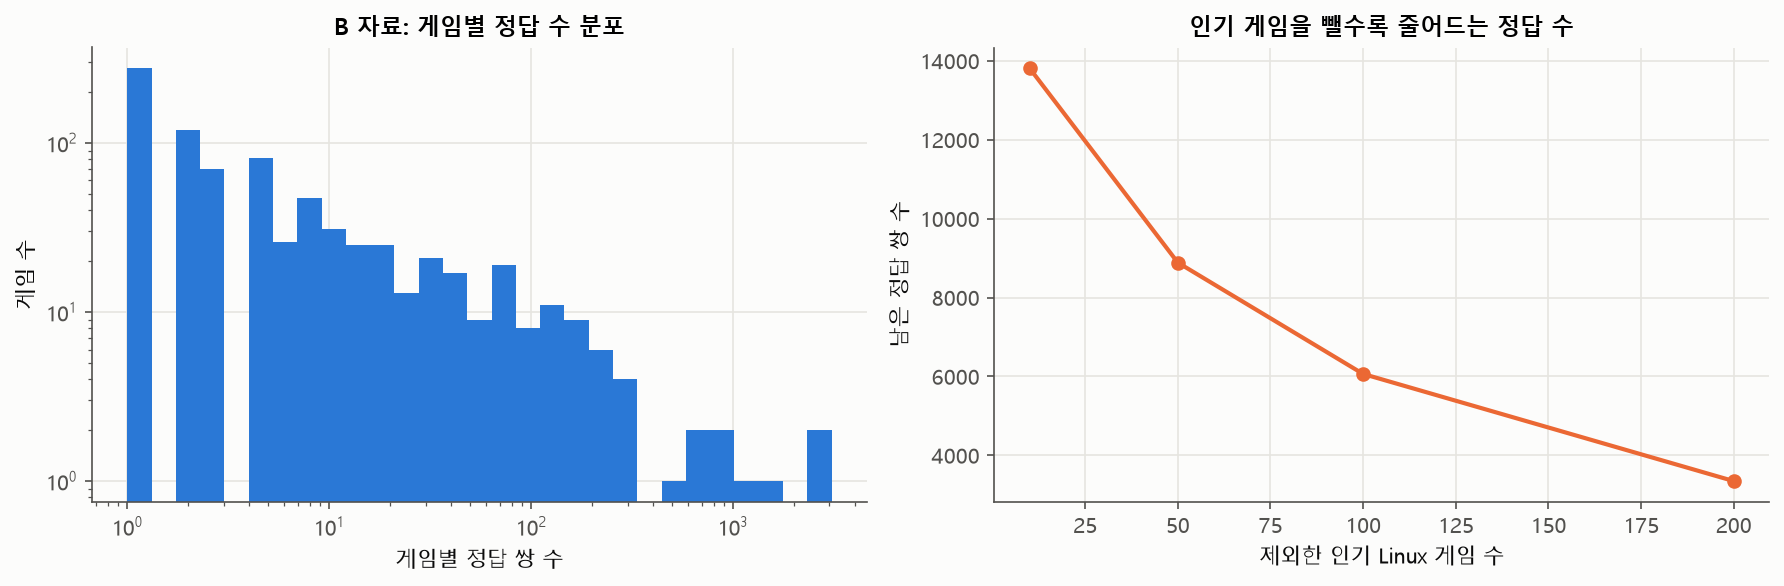

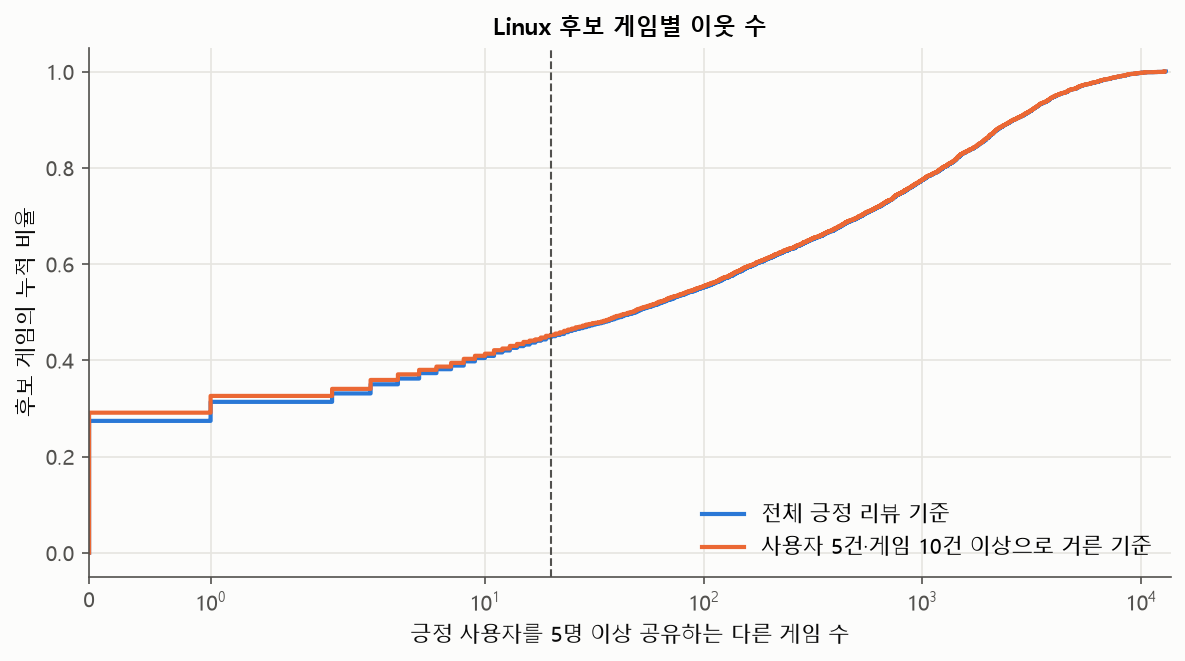

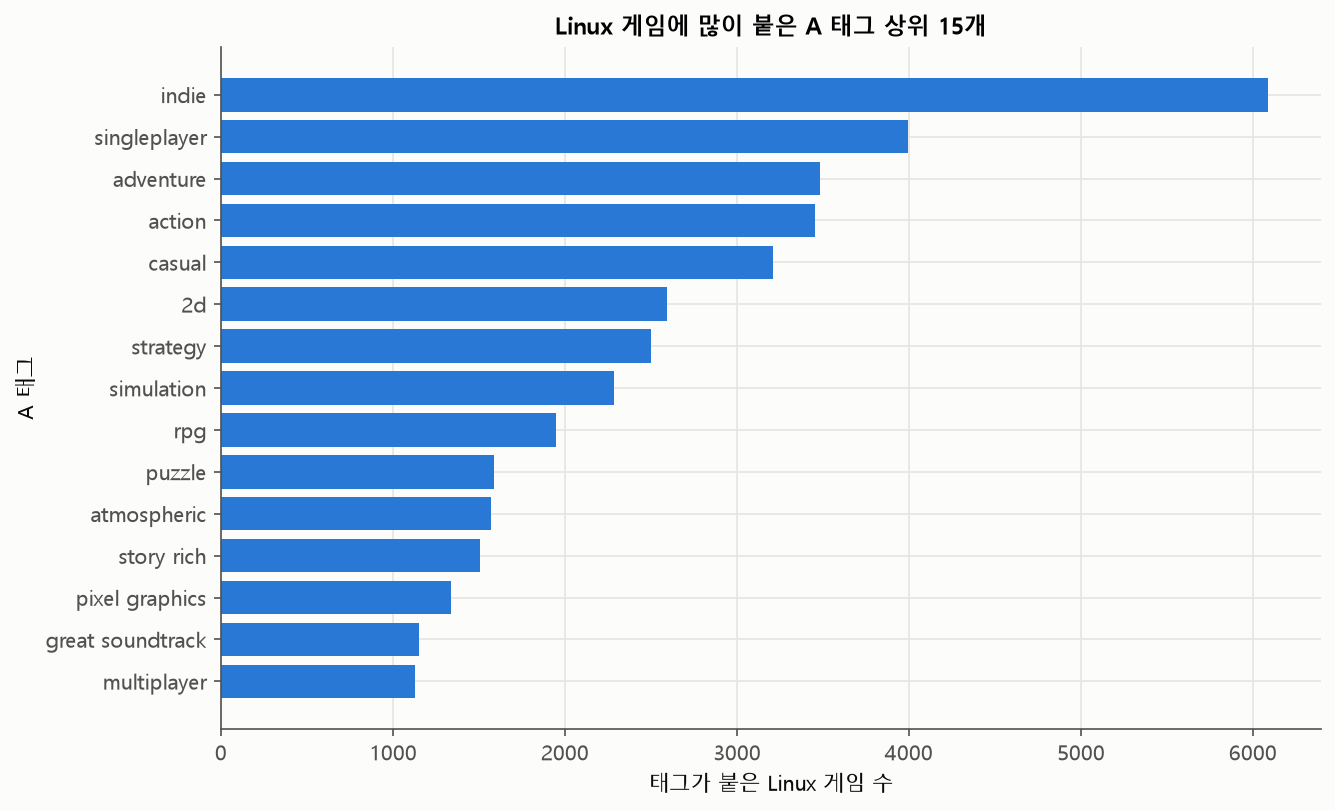

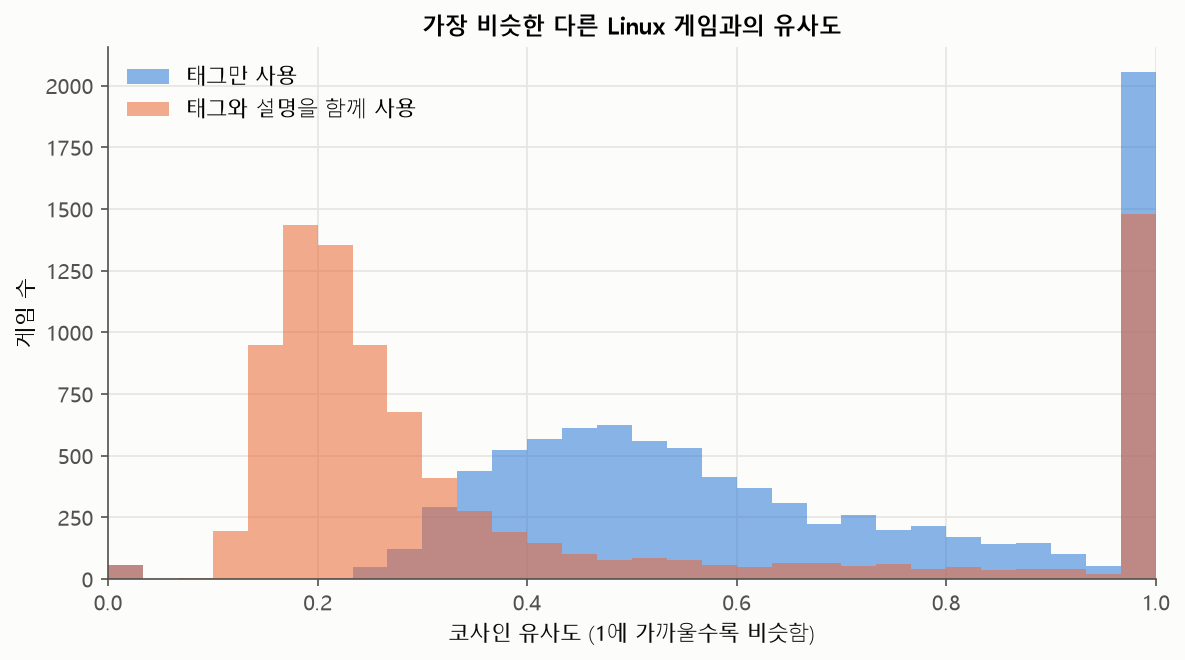

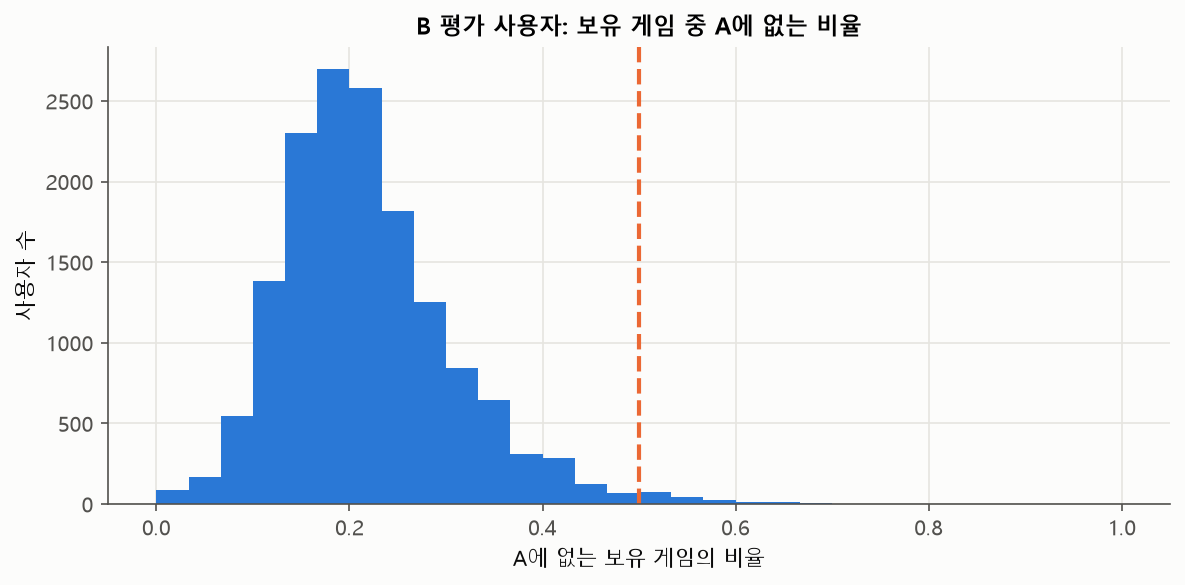

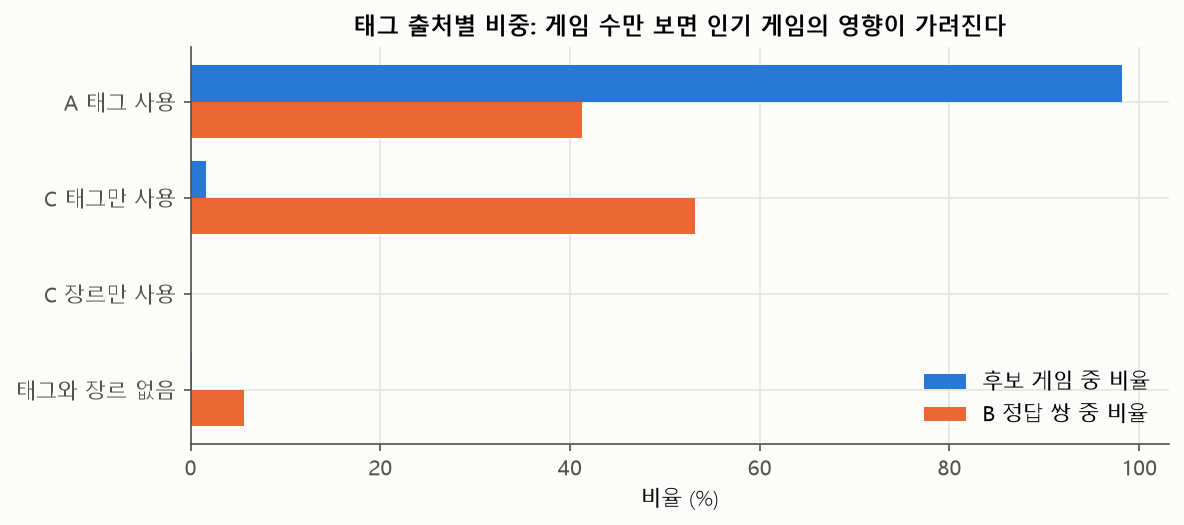

In [23]:
display(pd.DataFrame(decisions))
display(pd.DataFrame(RESULTS['A_label_coverage'], index=[0]).drop(columns='target_pair_distribution'))
display(pd.DataFrame(neighbors)[['source','candidate_games','insufficient_games','insufficient_pct']])
display(pd.DataFrame(ci))
from IPython.display import Image as NotebookImage
for figure_name in ['fig07_label_sufficiency', 'fig08_cooccurrence_support',
                    'fig09_A_linux_top_tags', 'fig10_tfidf_nearest_similarity', 'fig11_B_input_loss',
                    'fig12_tag_source_weighted']:
    display(NotebookImage(filename=str(FIG/f'{figure_name}.png')))